# Project 2 on Machine Learning: classification and regression, writing our own neural network code

**Data Analysis and Machine Learning FYS-STK3155/FYS4155, University of Oslo, fall 2026**

In [26]:
# Part a) is analytical and belongs in the theory section of your report.
# You may want to define the cost functions, their gradients and the
# activation functions (with derivatives) here as Python functions.

### imports
# basics
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import matplotlib.colors as mcolors
from matplotlib.ticker import LogFormatter
import matplotlib

# scikit
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.utils import resample
from sklearn import datasets

# jax
import jax
import jax.numpy as jnp
jax.config.update("jax_enable_x64", True)   # 64-bit floats, as in numpy

from IPython.display import Image

### import additional functions
from functions import *

### random seed for reproducibility
rng = np.random.default_rng(2026)

### defining colors and fontsize for plotting
BLUE, RED, GREEN, GREY = "#004488", "#BB5566", "#228833", "#777777"
train_color = "#32A911"
test_color = "#048582"

label_fontsize = 14
title_fontsize=16
tick_fontsize=13
legend_fontsize=11


In [27]:
def MSE(y_data, y_model):
    """from Tuesday lecture week 35"""
    return np.mean((y_data - y_model) ** 2)

def R2(y_data, y_model):
    """from Tuesday lecture week 35"""
    return 1.0 - np.sum((y_data - y_model) ** 2) / np.sum((y_data - np.mean(y_data)) ** 2)

# Functions from exercises
def cost(theta, X, y, lam=0.0):
    #if lambda == 0, this is OLS, otherwise Ridge
    return jnp.mean((y - X @ theta)**2) + lam * jnp.sum(theta**2)

def closed_form(X, y, lam=0.0):
    """Eq. (3.44) with the 1/n convention of Eq. (3.95): (X^T X + n lambda I)^-1 X^T y."""
    n, p = X.shape
    return np.linalg.solve(X.T @ X + n * lam * np.eye(p), X.T @ y)

def gradient(theta, X, y, lam=0.0):
    """Eqs. (4.13) and (4.17): the gradient of (1/n)||X theta - y||^2 + lambda theta^T theta."""
    n = len(y)
    return (2.0 / n) * X.T @ (X @ theta - y) + 2.0 * lam * theta


### Part b): Writing your own neural network code

(100, 1) (100,)


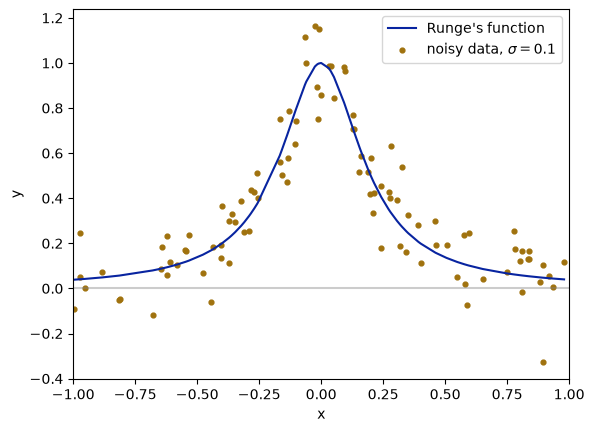

In [28]:
# The data of project 1, as a starting point for part b)
import numpy as np
import matplotlib.pyplot as plt

def runge(x):
    return 1.0 / (1.0 + 25.0 * x**2)

rng = np.random.default_rng(2026)      # fix the seed for reproducible results
n = 100
x = np.sort(rng.uniform(-1.0, 1.0, n))
sigma = 0.1
y = runge(x) + rng.normal(0.0, sigma, n)

# For the network the input is the raw x (one feature), samples in rows
X = x.reshape(-1, 1)
print(X.shape, y.shape)

plt.plot(x, runge(x), color="#0824A0", label="Runge's function")
plt.scatter(x, y, s=12, color="#A0720E", label=rf"noisy data, $\sigma={sigma}$")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(frameon=False)
plt.xlim(-1,1)
plt.plot([-1,1], [0,0], color='grey', linestyle='-', alpha=0.4)
plt.legend()
plt.show()


In [29]:
# Your code for part b) here

#Functions to do the backpropagation and feed forward

def create_layers(network_input_size, layer_output_sizes):
    layers = []

    i_size = network_input_size
    for layer_output_size in layer_output_sizes:
        W = np.random.randn(layer_output_size, i_size)
        b = np.random.randn(layer_output_size)
        layers.append((W, b))

        i_size = layer_output_size
    return layers

def feed_forward(input, layers, activation_funcs):
    a = input
    for (W, b), activation_func in zip(layers, activation_funcs):
        z = W @ a + b
        a = activation_func(z)
    return a

def cost(layers, input, activation_funcs, target):
    predict = feed_forward(input, layers, activation_funcs)
    return mse(predict, target)

def feed_forward_saver(input, layers, activation_funcs):
    layer_inputs = []
    zs = []
    a = input
    for (W, b), activation_func in zip(layers, activation_funcs):
        layer_inputs.append(a)
        z = W @ a + b
        a = activation_func(z)

        zs.append(z)

    return layer_inputs, zs, a



def backpropagation(
    input, layers, activation_funcs, target, activation_ders, cost_der=mse_der
):
    layer_inputs, zs, predict = feed_forward_saver(input, layers, activation_funcs)

    layer_grads = [() for layer in layers]

    # We loop over the layers, from the last to the first
    for i in reversed(range(len(layers))):
        layer_input, z, activation_der = layer_inputs[i], zs[i], activation_ders[i]

        if i == len(layers) - 1:
            # For last layer we use cost derivative as dC_da(L) can be computed directly
            dC_da = cost_der(predict, target)
        else:
            # For other layers we build on previous z derivative, as dC_da(i) = dC_dz(i+1) * dz(i+1)_da(i)
            (W, b) = layers[i + 1]
            dC_da = W.T @ dC_dz

        dC_dz = dC_da * activation_der(z)
        dC_dW = np.outer(dC_dz, layer_input)
        dC_db = dC_dz

        layer_grads[i] = (dC_dW, dC_db)

    return layer_grads

def create_layers_batch(network_input_size, layer_output_sizes):
    layers = []
    i_size = network_input_size
    for layer_output_size in layer_output_sizes:
        W = np.random.randn(i_size, layer_output_size)
        b = np.random.randn(layer_output_size)
        layers.append((W, b))
        i_size = layer_output_size
    return layers


def feed_forward_batch(inputs, layers, activation_funcs):
    a = inputs
    for (W, b), activation_func in zip(layers, activation_funcs):
        a = activation_func(a @ W + b)
    return a


def feed_forward_saver_batch(inputs, layers, activation_funcs):
    layer_inputs, zs = [], []
    a = inputs
    for (W, b), activation_func in zip(layers, activation_funcs):
        layer_inputs.append(a)
        z = a @ W + b
        a = activation_func(z)
        zs.append(z)
    return layer_inputs, zs, a


def mse_der_batch(predict, target):
    return 2 * (predict - target) / predict.size


def cost_batch(layers, inputs, activation_funcs, targets):
    return mse(feed_forward_batch(inputs, layers, activation_funcs), targets)

def output_error_softmax_ce(predict, target):
    return predict - target          # delta^L = a^L - y, Eq. (8.69)


def backpropagation_batch(
    inputs, layers, activation_funcs, targets, activation_ders, cost_der=mse_der_batch, output_error=None,
):
    layer_inputs, zs, predict = feed_forward_saver_batch(inputs, layers, activation_funcs)
    layer_grads = [() for layer in layers]

    for i in reversed(range(len(layers))):
        layer_input, z, activation_der = layer_inputs[i], zs[i], activation_ders[i]
        if i == len(layers) - 1 and output_error is not None:
            dC_dz = output_error(predict, targets)          # the shortcut: softmax + cross entropy
        else:
            if i == len(layers) - 1:
                dC_da = cost_der(predict, targets)
            else:
                (W, b) = layers[i + 1]
                dC_da = dC_dz @ W.T                 # samples stay in the rows
            dC_dz = dC_da * activation_der(z)       # (n, n_out), one error vector per sample
        dC_dW = layer_input.T @ dC_dz           # sum over the samples of the outer products
        dC_db = np.sum(dC_dz, axis=0)           # sum over the samples of the errors
        layer_grads[i] = (dC_dW, dC_db)

    return layer_grads


In [30]:

#TEST on the functions above:
inputs = np.random.rand(1000, 4)

layers_b = create_layers_batch(4, [6, 5, 3])
layers_single = [(W.T, b) for W, b in layers_b]
out_batch = feed_forward_batch(inputs, layers_b, [ReLU, ReLU, sigmoid])
out_single = feed_forward(inputs[0], layers_single, [ReLU, ReLU, sigmoid])
print(out_batch.shape)
print("max difference on sample 0:", np.max(np.abs(out_batch[0] - out_single)))


#Testing the code with jax, both for single input and batch input
network_input_size = 2
layer_output_sizes = [3, 4]
activation_funcs = [sigmoid, ReLU]
activation_ders = [sigmoid_der, ReLU_der]

layers = create_layers(network_input_size, layer_output_sizes)

xx = np.random.rand(network_input_size)
target = np.random.rand(4)

layer_grads = backpropagation(xx, layers, activation_funcs, target, activation_ders)

cost_grad = jax.grad(cost, argnums=0)
layer_grads_jax = cost_grad(layers, xx, [sigmoid, ReLU], target)

# checking that the functions above agree with jax to machine precision
print([ (np.allclose(dW, dW_j), np.allclose(db, db_j))
        for (dW, db), (dW_j, db_j) in zip(layer_grads, layer_grads_jax) ])


inputs = np.random.rand(10, 2)
targets = np.random.rand(10, 4)
layers_b = create_layers_batch(2, [3, 4])

g_hand = backpropagation_batch(inputs, layers_b, activation_funcs, targets, activation_ders)
g_jax = jax.grad(cost_batch, argnums=0)(layers_b, inputs, activation_funcs, targets)

for (dW, db), (dW_j, db_j) in zip(g_hand, g_jax):
    print("dW", dW.shape, np.allclose(dW, dW_j), "   db", db.shape, np.allclose(db, db_j))

(1000, 3)
max difference on sample 0: 1.1102230246251565e-16
[(True, True), (True, True)]
dW (2, 3) True    db (3,) True
dW (3, 4) True    db (4,) True


In [31]:
# standardised features and an 80/20 split, as in the week-41 solutions
from sklearn.model_selection import train_test_split

#initialise the weights and biases
def init_layers(sizes, seed):
    rng = np.random.default_rng(seed)
    return [(rng.standard_normal((n_in, n_out)) / np.sqrt(n_in), np.random.rand(n_out)*1e-9) #weights are initialised with a normal distribution with mean 0 and variance 1/n_in, biases are initialised to very small random values
            for n_in, n_out in zip(sizes[:-1], sizes[1:])]

#using MSE as the cost function:
def cost_batch(layers, inputs, activation_funcs, targets):
    return mse(feed_forward_batch(inputs, layers, activation_funcs), targets)


#setting up the input and target data:
def prepare_data(x,y):
    """splits into train and test, prepares design matrix and scales data"""

    #split into train and test data
    x_tr, x_te, y_tr, y_te = train_test_split(x, y, test_size=0.2, random_state=2026)

    # create design matrix, expanding the dimensions of x and y to make them 2D arrays with one column each
    X_train = np.expand_dims(x_tr, axis=1)
    X_test = np.expand_dims(x_te, axis=1) 

    #need to expand the dimensions of y as well, to make it a 2D array with one column
    y_tr = np.expand_dims(y_tr, axis=1)
    y_te = np.expand_dims(y_te, axis=1)

    #centering and scaling the data
    x_tr_std = (X_train - X_train.mean(axis=0)) / X_train.std(axis=0)
    y_tr_norm = y_tr# - y_tr.mean(axis=0)

    x_te_std = (X_test - X_train.mean(axis=0)) / X_train.std(axis=0)
    y_te_norm = y_te# - y_te.mean(axis=0)

    return x_tr_std, x_te_std, y_tr_norm, y_te_norm


#From weekly exercises, incorporated into the optimiser_step function
def gd_step(layers, grads, gamma, state=None):
    """Plain gradient descent on a list of (W, b): theta <- theta - gamma * grad."""
    return [(W - gamma * dW, b - gamma * db) for (W, b), (dW, db) in zip(layers, grads)], state

def momentum_step(layers, grads, gamma, state=None, beta=0.9):
    """SGD with momentum: v <- beta v + gamma grad, theta <- theta - v.
    The velocities live in `state`, one (vW, vb) per layer."""
    if state is None:
        state = [(np.zeros_like(W), np.zeros_like(b)) for W, b in layers]
    state = [(beta * vW + gamma * dW, beta * vb + gamma * db) for (vW, vb), (dW, db) in zip(state, grads)]
    layers = [(W - vW, b - vb) for (W, b), (vW, vb) in zip(layers, state)]
    return layers, state


#Function from exercises, equations for various methods with gradient descent 
#help from copilot with in-line suggestions based on the original function with linear regression, that was looked through before (if) accepted
def optimiser_step(method, layers, grads, gamma, t,state=None, beta=0.9, rho=0.99,
                   beta1=0.9, beta2=0.999, eps=1e-8):
    """One update of theta from the gradient g at step t (t = 1, 2, ...), Eqs. (4.10), (4.28),
    (4.42)-(4.45), (4.47)-(4.48) and (4.51)-(4.55).  state carries the running quantities."""
    if method == "plain":
        return [(W - gamma * dW, b - gamma * db) for (W, b), (dW, db) in zip(layers, grads)], state #theta - gamma * g, state
    if method == "momentum":
        if state is None:
            state = [(np.zeros_like(W), np.zeros_like(b)) for W, b in layers]
        state = [(beta * vW + gamma * dW, beta * vb + gamma * db) for (vW, vb), (dW, db) in zip(state, grads)]
        layers = [(W - vW, b - vb) for (W, b), (vW, vb) in zip(layers, state)]
        return layers, state
    if method == "rmsprop":
        if state is None:
            state = [(np.zeros_like(W), np.zeros_like(b)) for W, b in layers]
        state = [(rho * rW + (1.0 - rho) * dW * dW, rho * rb + (1.0 - rho) * db * db) for (rW, rb), (dW, db) in zip(state, grads)]
        layers = [(W - gamma * dW / (np.sqrt(rW) + eps), b - gamma * db / (np.sqrt(rb) + eps)) for (W, b), (dW, db), (rW, rb) in zip(layers, grads, state)]
        return layers, state  
    if method == "adam": #help from local chat to debug the code and come with suggestions for fix for adam implementation
        if state is None:
            m_state = [(np.zeros_like(W), np.zeros_like(b)) for W, b in layers]
            r_state = [(np.zeros_like(W), np.zeros_like(b)) for W, b in layers]      
        else:
            m_state, r_state = state
        m_state = [(beta1 * mW + (1.0 - beta1) * dW, beta1 * mb + (1.0 - beta1) * db) for (mW, mb), (dW, db) in zip(m_state, grads)]
        r_state = [(beta2 * rW + (1.0 - beta2) * dW * dW, beta2 * rb + (1.0 - beta2) * db * db) for (rW, rb), (dW, db) in zip(r_state, grads)]
        state = [m_state,r_state]
        layers = [(W - gamma * (mW / (1.0 - beta1**t)) / (np.sqrt(rW / (1.0 - beta2**t)) + eps), b - gamma * (mb / (1.0 - beta1**t)) / (np.sqrt(rb / (1.0 - beta2**t)) + eps)) for (W, b), (mW, mb), (rW, rb) in zip(layers, m_state, r_state)]
        return layers, state 
    raise ValueError(f"unknown method {method}")


def OLS_regression(X, y):
    """ set up the design function, based on a 5th degree polynomial, and return the closed form solution with y tilde as the predicted target"""
    theta = closed_form(np.column_stack([X**i for i in range(6)]), y)

    predict_OLS = np.polyval(theta[::-1], X)

    return predict_OLS

def predict(X, layers, hidden_activation="sigmoid"):
    """The output of the network"""
    return feed_forward_batch(X, layers, hidden_activation)



#function from exercises, tweaked to match the project
def train(layers, X, y, X_test, y_test, step, act, act_der, gamma, epochs, batch_size=None, seed=2026):
    """batch_size=None: full-batch gradient descent; otherwise minibatches drawn without
    replacement from a fresh shuffle every epoch.  Returns the trained layers and a history
    of (epoch, training cost, test accuracy)."""
    rng = np.random.default_rng(seed)
    n = len(X)
    M = n if batch_size is None else batch_size
    state, history = None, []
    t = 0
    prediction = []
    for epoch in range(1, epochs + 1):
        perm = rng.permutation(n)
        for start in range(0, n, M):
            
            idx = perm[start:start + M]
            grads = backpropagation_batch(X[idx], layers, act, y[idx], act_der)

            t += 1
            layers, state = optimiser_step(step, layers, grads, gamma, t, state)

        #The MSE as cost, for train and test data
        history.append((epoch, float(cost_batch(layers, X, act, y)),float(cost_batch(layers, X_test, act, y_test))))
        prediction.append(feed_forward_batch(X_test, layers, act)) 
    return layers, np.array(history), prediction

def setup_NN(
    X_shape,
    y_shape,
    design_hidden:list,
    activation_funcs:callable=ReLU,
    activation_ders:callable=ReLU_der,
    activation_output: callable=identity,
    activation_output_der: callable=identity_der,
):
    """Set up a neural network with the layers and activation functions."""
    layers = init_layers([X_shape[1]] + design_hidden + [y_shape[1]], seed=2026)
    activation_funcs = [activation_funcs] * len(design_hidden) + [activation_output]
    activation_ders = [activation_ders] * len(design_hidden) + [activation_output_der]

    return layers, activation_funcs, activation_ders



[(True, True), (True, True)]
noise level based on the test data: 0.0096  (sigma^2 = 0.010000000000000002)
epoch   GD 50x1: cost  test diff     GD 100x2: cost  test diff
    1        0.76   0.636                0.19   0.157
    2        0.72   0.605                0.18   0.151
    5        0.63   0.524                0.16   0.138
   10        0.50   0.418                0.13   0.128
   20        0.33   0.281                0.11   0.127
   50        0.14   0.154                0.10   0.139
  100        0.10   0.146                0.10   0.142
  200        0.10   0.150                0.10   0.142
  500        0.09   0.145                0.10   0.141
 1000        0.09   0.143                0.09   0.140
GD 50x1, 1000 epochs      train cost 0.092   test cost 0.143
GD 100x2, 1000 epochs     train cost 0.094   test cost 0.140


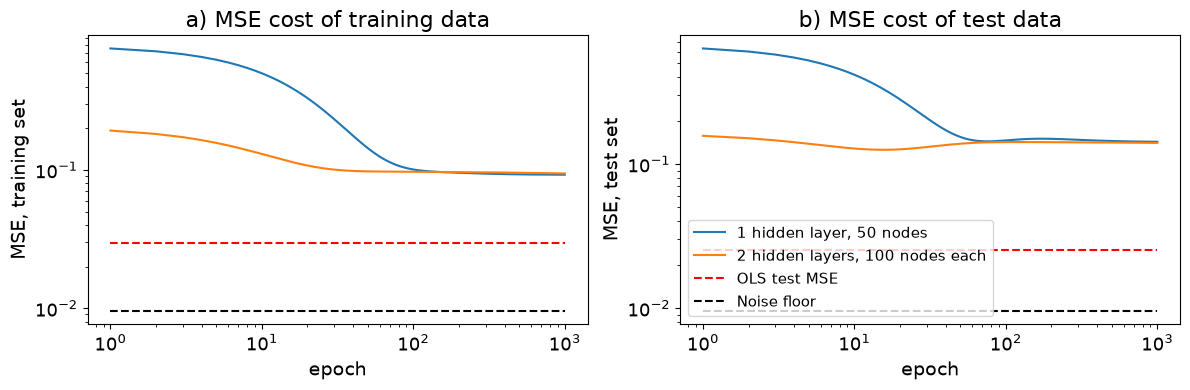

MSE train OLS: 0.029506814559850648
MSE test OLS: 0.025490471098851625


In [32]:


# Preapring data for training and testing
x_tr, x_te, y_tr, y_te = prepare_data(x,y)

#Getting the target values from closed form solution of OLS to compare with the neural network
prediction_OLS = OLS_regression(x_te, y_te)

#Set up activation functions and their derivatives for the network, as well as initialising the weights and biases
layers0, activation_funcs, activation_ders = setup_NN(x_tr.shape, y_tr.shape, design_hidden=[50], activation_funcs=sigmoid, activation_ders=sigmoid_der, activation_output=identity, activation_output_der=identity_der)


#Testing with JAX:
g_hand = backpropagation_batch(x_tr, layers0, activation_funcs, y_tr, activation_ders)
g_jax = jax.grad(cost_batch, argnums=0)(layers0, x_tr, activation_funcs, y_tr)

# checking that the functions above agree with JAX to machine precision
print([ (np.allclose(dW, dW_j), np.allclose(db, db_j))
        for (dW, db), (dW_j, db_j) in zip(g_hand, g_jax) ])



# Getting the noise floor on the test points
_, xtest, _, ytest = train_test_split(x, y, test_size=0.2, random_state=2026)
noise_floor = np.mean((ytest - runge(xtest)) ** 2)
print(f"noise level based on the test data: {noise_floor:.4f}  (sigma^2 = {sigma**2})")



#Compare the NN with 50 and 100 nodes and one and two hidden layers, with the closed form solution of OLS regression
layers_50, activation_funcs_50, activation_ders_50 = setup_NN(x_tr.shape, y_tr.shape, design_hidden=[50], activation_funcs=sigmoid, activation_ders=sigmoid_der, activation_output=identity, activation_output_der=identity_der)
layers_50,  hist_50, prediction_50  = train(layers_50, x_tr, y_tr, x_te, y_te, step="plain", act=activation_funcs_50, act_der=activation_ders_50, gamma=0.001, epochs=1000)

layers_100, activation_funcs_100, activation_ders_100 = setup_NN(x_tr.shape, y_tr.shape, design_hidden=[100,100], activation_funcs=sigmoid, activation_ders=sigmoid_der, activation_output=identity, activation_output_der=identity_der)
layers_100,  hist_100, prediction_100  = train(layers_100, x_tr, y_tr, x_te, y_te, step="plain", act=activation_funcs_100, act_der=activation_ders_100, gamma=0.001, epochs=1000)


print("epoch   GD 50x1: cost  test diff     GD 100x2: cost  test diff")
for e in [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]:
    g = hist_50[e - 1]
    s = hist_100[e - 1] if e <= len(hist_100) else None
    print("%5d     %7.2f   %.3f      " % (e, g[1], g[2])
          + ("       %7.2f   %.3f" % (s[1], s[2]) if s is not None else ""))

for name, L in [("GD 50x1, 1000 epochs", layers_50), ("GD 100x2, 1000 epochs", layers_100)]:
    print("%-25s train cost %.3f   test cost %.3f"
          % (name,  float(cost_batch(L, x_tr, activation_funcs_50 if L is layers_50 else activation_funcs_100, y_tr)),
             float(cost_batch(L, x_te, activation_funcs_50 if L is layers_50 else activation_funcs_100, y_te))))

#Plotting the results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.semilogy(hist_50[:, 0], hist_50[:, 1], label="1 hidden layer, 50 nodes")
ax1.semilogy(hist_100[:, 0], hist_100[:, 1], label="2 hidden layers, 100 nodes each")
ax1.hlines(MSE(OLS_regression(x_tr, y_tr),y_tr), xmin=hist_50[0, 0], xmax=hist_50[-1, 0], colors='r', linestyles='dashed', label="OLS train MSE")
ax1.hlines(noise_floor, xmin=hist_50[0, 0], xmax=hist_50[-1, 0], colors='k', linestyles='dashed', label="Noise floor")

ax1.set_xlabel("epoch", fontsize=label_fontsize); ax1.set_ylabel("MSE, training set", fontsize=label_fontsize); ax1.set_xscale("log")#; ax1.set_yscale("log")
ax1.set_title("a) MSE cost of training data", fontsize=title_fontsize)
ax1.tick_params(axis='both', which='major', labelsize=tick_fontsize)
ax2.semilogy(hist_50[:, 0], hist_50[:, 2], label="1 hidden layer, 50 nodes")
ax2.semilogy(hist_100[:, 0], hist_100[:, 2], label="2 hidden layers, 100 nodes each")
ax2.hlines(MSE(OLS_regression(x_te, y_te),y_te), xmin=hist_50[0, 0], xmax=hist_50[-1, 0], colors='r', linestyles='dashed', label="OLS test MSE")
ax2.hlines(noise_floor, xmin=hist_50[0, 0], xmax=hist_50[-1, 0], colors='k', linestyles='dashed', label="Noise floor")
ax2.set_xlabel("epoch", fontsize=label_fontsize); ax2.set_ylabel("MSE, test set", fontsize=label_fontsize); ax2.set_xscale("log")
ax2.set_title("b) MSE cost of test data",fontsize=title_fontsize)
ax2.tick_params(axis='both', which='major', labelsize=tick_fontsize)
ax2.legend(fontsize=legend_fontsize,loc="best")


# fig.suptitle("Comparison of hidden layers and nodes")
plt.tight_layout()
plt.savefig("./figures/NN_50x1_100x2.png", dpi=500)
plt.show()


print("MSE train OLS:", MSE(OLS_regression(x_tr, y_tr),y_tr))
print("MSE test OLS:", MSE(OLS_regression(x_te, y_te),y_te))


<>:45: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
<>:45: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
C:\Users\lukasjm\AppData\Local\Temp\ipykernel_32432\2528852126.py:45: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
  ax.add_patch(plt.Rectangle((gammas.index((np.array(gammas)[within[0]])[0]) - 0.5, np.nanmin(grid_gammas[name])-8e-3), 1, 2e-2, fill=False, edgecolor="black", lw=3, linestyle="--",zorder=2,label="min $\gamma$ within 1 se"))


CV MSE with learning rate 0.0001: 0.1024
CV MSE with learning rate 0.0002: 0.0971
CV MSE with learning rate 0.0005: 0.0955
CV MSE with learning rate 0.001: 0.0955
CV MSE with learning rate 0.002: 0.0954
CV MSE with learning rate 0.005: 0.0949
CV MSE with learning rate 0.01: 0.0949
CV MSE with learning rate 0.02: 0.0971
CV MSE with learning rate 0.05: 0.0970
CV MSE with learning rate 0.1: 0.0350
CV MSE with learning rate 0.5: nan
CV MSE with learning rate 0.0001: 0.0909
CV MSE with learning rate 0.0002: 0.0872
CV MSE with learning rate 0.0005: 0.0734
CV MSE with learning rate 0.001: 0.0453
CV MSE with learning rate 0.002: 0.0303
CV MSE with learning rate 0.005: 0.0292
CV MSE with learning rate 0.01: 0.0323
CV MSE with learning rate 0.02: 0.0352
CV MSE with learning rate 0.05: 0.0364
CV MSE with learning rate 0.1: 0.0401
CV MSE with learning rate 0.5: 0.1762
CV MSE with learning rate 0.0001: 0.0924
CV MSE with learning rate 0.0002: 0.0907
CV MSE with learning rate 0.0005: 0.0830
CV MSE w

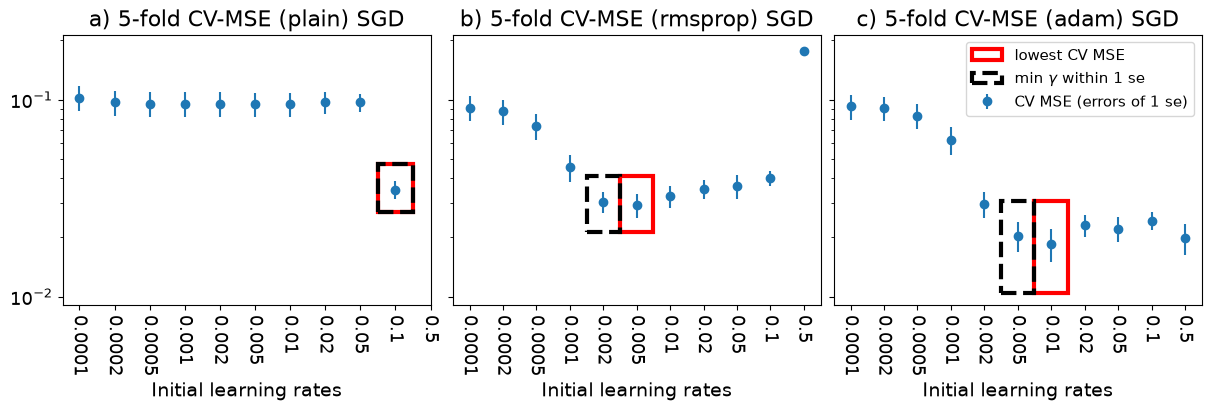

In [33]:
# Cross-validation to find the best learning rate for each of the three different SGD methods, based on the CV MSE

def cv_mse_nopen(hidden, nlayer, gamma=0.01, lam=0, norm=None, k=5, epochs=200, activation=sigmoid,activation_der=sigmoid_der,step="adam"):
    """5-fold CV MSE on the training data for one network setting. The validation MSE of a fold is
    averaged over the last 10 epochs, to remove jittering."""
    scores = []
    for tr, va in KFold(k, shuffle=True, random_state=2026).split(x_tr):
        layers, act, der = setup_NN(x_tr.shape, y_tr.shape, design_hidden=nlayer*[hidden], activation_funcs=activation, activation_ders=activation_der, activation_output=identity, activation_output_der=identity_der)
        _, hist, _ = train(layers, x_tr[tr], y_tr[tr], x_tr[va], y_tr[va],
                                  step, act, der, gamma, epochs,batch_size=15)

        scores.append(hist[-10:, 2].mean())
    return float(np.mean(scores)), float(np.std(scores))/np.sqrt(len(scores))


gammas = [0.0001,0.0002,0.0005,0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.5]

#Looping over different gammas for the three different SGD methods, to find the best learning rate for each method, based on the CV MSE
grid_gammas = {}
grid_se = {}
for name in ["plain","rmsprop","adam"]:
    score_mean = []
    score_se = []
    for gamma in gammas:

        mean, se = cv_mse_nopen(50, 1, gamma, activation=sigmoid,activation_der=sigmoid_der,step=name)
        score_mean.append(mean)
        score_se.append(se)
        print(f"CV MSE with learning rate {gamma}: {mean:.4f}")
    
    grid_gammas[name], grid_se[name] = np.array(score_mean).reshape(1, len(gammas)), np.array(score_se).reshape(1, len(gammas))  
inds = ["a", "b", "c"]
eb_colors = []
fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True,sharey=True)
for ax, name, ind in zip(axes, ["plain", "rmsprop", "adam"], inds):

    markers,_,lines = ax.errorbar(np.arange(len(gammas)), grid_gammas[name][0], yerr = grid_se[name], fmt='o',label="CV MSE (errors of 1 se)")
    i_best = np.unravel_index(np.nanargmin(grid_gammas[name]), grid_gammas[name].shape)
    within = grid_gammas[name] <= grid_gammas[name][i_best] + grid_se[name][i_best]
        
    print("Learning rates that achieve CV MSE within 1 standard error of the best:", np.array(gammas)[within[0]], f"({name})")
    ax.add_patch(plt.Rectangle((i_best[1] - 0.5, np.nanmin(grid_gammas[name])-8e-3), 1, 2e-2, fill=False, edgecolor="red", lw=3,zorder=1,label="lowest CV MSE")) 

    print("Minimum learning rate within 1 standard error:", (np.array(gammas)[within[0]])[0], f"({name})")
    ax.add_patch(plt.Rectangle((gammas.index((np.array(gammas)[within[0]])[0]) - 0.5, np.nanmin(grid_gammas[name])-8e-3), 1, 2e-2, fill=False, edgecolor="black", lw=3, linestyle="--",zorder=2,label="min $\gamma$ within 1 se")) 
        
    ax.set_yscale("log")
    
    ax.set_xticks(np.arange(len(gammas)))
    ax.set_xticklabels(gammas,rotation=270)
    ax.set_xlabel("Initial learning rates", fontsize=label_fontsize)
    ax.set_title(f"{ind}) 5-fold CV-MSE ({name}) SGD", fontsize=title_fontsize)
    ax.tick_params(axis='both', which='both', labelsize=tick_fontsize)
    
axes[2].legend(fontsize=legend_fontsize,loc="upper right")
    
# fig.suptitle("5-fold CV MSE",fontsize=title_fontsize)
plt.savefig("./figures/partb_gammas.png", dpi=500)
plt.show()



epoch   GD: cost  test diff     SGD+adam: cost  test diff    SGD+rmsprop: cost  test diff
    1      175.79   173.879                0.10   0.143          0.10   0.128
    2        0.17   0.295                0.16   0.281          0.10   0.164
    5        0.09   0.134                0.10   0.122          0.09   0.136
   10        0.13   0.221                0.09   0.134          0.10   0.166
   20        0.08   0.096                0.08   0.119          0.08   0.113
   50        0.04   0.066                0.04   0.062          0.06   0.094
  100        0.03   0.042                0.02   0.024          0.03   0.044
  200        0.03   0.031                0.02   0.015          0.02   0.025
GD, 1000 epochs           train cost 0.026   test cost 0.031
SGD+adam, 200 epochs      train cost 0.016   test cost 0.015
SGD+rmsprop, 200 epochs   train cost 0.022   test cost 0.025


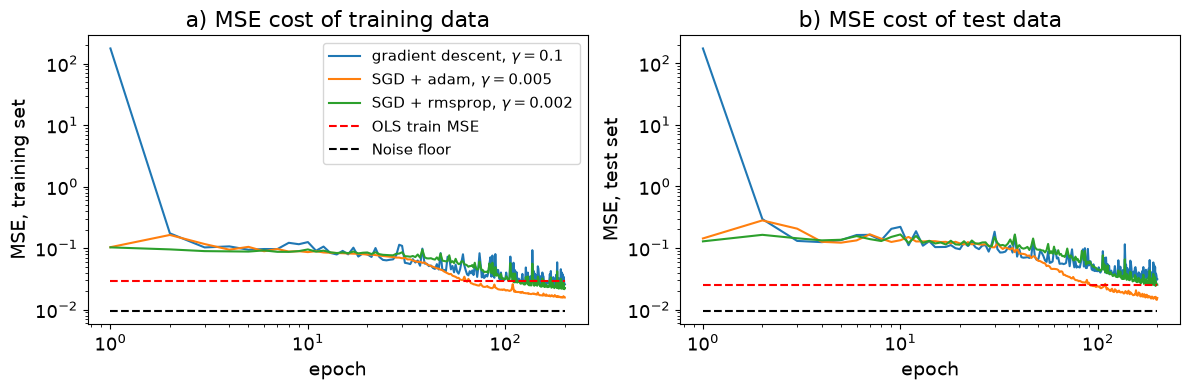

In [34]:
#Comparing plain GD with SGD Adam and RMSprop, with 1 hidden layer and 50 nodes

#Set up activation functions and their derivatives for the network, as well as initialising the weights and biases
layers0, activation_funcs, activation_ders = setup_NN(X.shape, y_tr.shape, design_hidden=[50], activation_funcs=sigmoid, activation_ders=sigmoid_der, activation_output=identity, activation_output_der=identity_der)


#Train the datasets with different optimiser steps
layers_gd,  hist_gd, prediction_gd  = train(layers0, x_tr, y_tr, x_te, y_te, step="plain", act=activation_funcs, act_der=activation_ders, gamma=0.1, epochs=200,batch_size=15)
layers_adam, hist_adam, prediction_adam = train(layers0, x_tr, y_tr, x_te, y_te, step="adam", act=activation_funcs, act_der=activation_ders, gamma=0.005,  epochs=200, batch_size=15)
layers_rmsprop, hist_rmsprop, prediction_rmsprop = train(layers0, x_tr, y_tr, x_te, y_te, step="rmsprop", act=activation_funcs, act_der=activation_ders, gamma=0.002,  epochs=200, batch_size=15)

print("epoch   GD: cost  test diff     SGD+adam: cost  test diff    SGD+rmsprop: cost  test diff")
for e in [1, 2, 5, 10, 20, 50, 100, 200]:
    g = hist_gd[e - 1]
    a = hist_adam[e - 1] if e <= len(hist_adam) else None
    r = hist_rmsprop[e - 1] if e <= len(hist_rmsprop) else None
    print("%5d     %7.2f   %.3f      " % (e, g[1], g[2])
          + ("       %7.2f   %.3f" % (a[1], a[2]) if a is not None else "")
          + ("       %7.2f   %.3f" % (r[1], r[2]) if r is not None else ""))

for name, L in [("GD, 1000 epochs", layers_gd), ("SGD+adam, 200 epochs", layers_adam), ("SGD+rmsprop, 200 epochs", layers_rmsprop)]:
    print("%-25s train cost %.3f   test cost %.3f"
          % (name,  float(cost_batch(L, x_tr, activation_funcs, y_tr)),
             float(cost_batch(L, x_te, activation_funcs, y_te))))
    
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(hist_gd[:, 0], hist_gd[:, 1], label="gradient descent, $\\gamma=0.1$")
ax1.plot(hist_adam[:, 0], hist_adam[:, 1], label="SGD + adam, $\\gamma=0.005$")
ax1.plot(hist_rmsprop[:, 0], hist_rmsprop[:, 1], label="SGD + rmsprop, $\\gamma=0.002$")
ax1.hlines(MSE(OLS_regression(x_tr, y_tr),y_tr), xmin=hist_gd[0, 0], xmax=hist_gd[-1, 0], colors='r', linestyles='dashed', label="OLS train MSE")
ax1.hlines(noise_floor, xmin=hist_gd[0, 0], xmax=hist_gd[-1, 0], colors='k', linestyles='dashed', label="Noise floor")
ax1.set_xlabel("epoch", fontsize=label_fontsize); ax1.set_ylabel("MSE, training set", fontsize=label_fontsize); ax1.set_xscale("log"); ax1.set_yscale("log"); ax1.legend(fontsize=legend_fontsize)
ax1.set_title("a) MSE cost of training data", fontsize=title_fontsize)
ax1.tick_params(axis='both', which='both', labelsize=tick_fontsize)


ax2.semilogy(hist_gd[:, 0], hist_gd[:, 2])
ax2.semilogy(hist_adam[:, 0], hist_adam[:, 2])
ax2.semilogy(hist_rmsprop[:, 0], hist_rmsprop[:, 2])
ax2.hlines(MSE(OLS_regression(x_te, y_te),y_te), xmin=hist_gd[0, 0], xmax=hist_gd[-1, 0], colors='r', linestyles='dashed', label="OLS test MSE")
ax2.hlines(noise_floor, xmin=hist_gd[0, 0], xmax=hist_gd[-1, 0], colors='k', linestyles='dashed', label="Noise floor")
ax2.set_xlabel("epoch", fontsize=label_fontsize); ax2.set_ylabel("MSE, test set", fontsize=label_fontsize); ax2.set_xscale("log")#; ax2.set_ylim(0, 0.4)
ax2.set_title("b) MSE cost of test data", fontsize=title_fontsize)
ax2.tick_params(axis='both', which='both', labelsize=tick_fontsize)

# fig.suptitle("Skill of different optimiser methods", fontsize=title_fontsize)
plt.tight_layout()
plt.savefig("./figures/NN_optimiser_comparison.png", dpi=500)
plt.show()



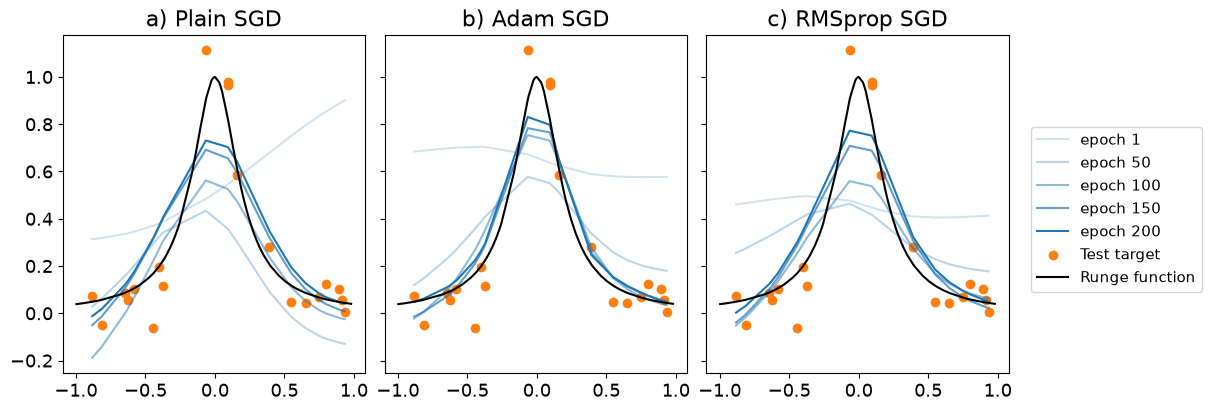

In [35]:

#Getting the raw data to plot with the Runge function
x_tr_raw, x_te_raw, _, _ = train_test_split(x, y, test_size=0.2, random_state=2026)

order = np.argsort(x_te_raw)

fig, ax = plt.subplots(1,3, figsize=(12, 4),sharey=True, constrained_layout=True)
ax[0].plot(x_te_raw[order], prediction_gd[1][order, 0],  label="epoch 1",color="tab:blue",alpha=0.2)
ax[0].plot(x_te_raw[order], prediction_gd[50][order, 0],  label="epoch 50",color="tab:blue",alpha=0.3)
ax[0].plot(x_te_raw[order], prediction_gd[100][order, 0],  label="epoch 100",color="tab:blue",alpha=0.5)
ax[0].plot(x_te_raw[order], prediction_gd[150][order, 0],  label="epoch 150",color="tab:blue",alpha=0.7)
ax[0].plot(x_te_raw[order], prediction_gd[-1][order, 0],  label="epoch 200",color="tab:blue",alpha=1)
ax[0].scatter(x_te_raw[order], y_te[order],  label="Test target",color="tab:orange",alpha=1)
ax[0].plot(x, runge(x), "k", label="Runge function")
ax[0].set_title("a) Plain SGD",fontsize=title_fontsize)
ax[0].tick_params(axis='both', which='both', labelsize=tick_fontsize)

ax[1].plot(x_te_raw[order], prediction_adam[1][order, 0],  label="epoch 1",color="tab:blue",alpha=0.2)
ax[1].plot(x_te_raw[order], prediction_adam[50][order, 0],  label="epoch 50",color="tab:blue",alpha=0.3)
ax[1].plot(x_te_raw[order], prediction_adam[100][order, 0],  label="epoch 100",color="tab:blue",alpha=0.5)
ax[1].plot(x_te_raw[order], prediction_adam[150][order, 0],  label="epoch 150",color="tab:blue",alpha=0.7)
ax[1].plot(x_te_raw[order], prediction_adam[-1][order, 0],  label="epoch 200",color="tab:blue",alpha=1)
ax[1].scatter(x_te_raw[order], y_te[order],  label="Test target",color="tab:orange",alpha=1)

ax[1].plot(x, runge(x), "k", label="Runge function")
ax[1].set_title("b) Adam SGD",fontsize=title_fontsize)
ax[1].tick_params(axis='both', which='both', labelsize=tick_fontsize)

ax[2].plot(x_te_raw[order], prediction_rmsprop[1][order, 0],  label="epoch 1",color="tab:blue",alpha=0.2)
ax[2].plot(x_te_raw[order], prediction_rmsprop[50][order, 0],  label="epoch 50",color="tab:blue",alpha=0.3)
ax[2].plot(x_te_raw[order], prediction_rmsprop[100][order, 0],  label="epoch 100",color="tab:blue",alpha=0.5)
ax[2].plot(x_te_raw[order], prediction_rmsprop[150][order, 0],  label="epoch 150",color="tab:blue",alpha=0.7)
ax[2].plot(x_te_raw[order], prediction_rmsprop[-1][order, 0],  label="epoch 200",color="tab:blue",alpha=1)
ax[2].scatter(x_te_raw[order], y_te[order],  label="Test target",color="tab:orange",alpha=1)

ax[2].plot(x, runge(x), "k", label="Runge function")
ax[2].set_title("c) RMSprop SGD",fontsize=title_fontsize)
ax[2].legend(bbox_to_anchor=(1.05, 0.75),fontsize=legend_fontsize)
ax[2].tick_params(axis='both', which='both', labelsize=tick_fontsize)

plt.savefig("./figures/optimiser_predict_comparison.png", dpi=500)
plt.show()

### Part c): Testing different activation functions and depths of the neural network

In [36]:

#function from part d but tweaked
def heatmap_nopen(ax, grid, row_labels, col_labels, title, ylabel, xlabel,vmin=0.01, vmax=0.2, grid_se=None):
    """Heat map of CV MSE (log colour scale) with the value written in every cell;
    the best cell gets a red frame."""
    cmap = plt.get_cmap("viridis_r")
    norm = LogNorm(vmin=vmin, vmax=vmax)
    ax.imshow(grid, cmap=cmap, norm=norm, aspect="auto")          # row 0 is drawn at the top
    
    i_best = np.unravel_index(np.argmin(grid), grid.shape)
    within = grid <= grid[i_best] + grid_se[i_best]

    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            r, g, b, _ = cmap(norm(grid[i, j]))                   # colour of this cell
            text_color = "white" if 0.299 * r + 0.587 * g + 0.114 * b < 0.5 else "black"   # readable on dark/light
            ax.text(j, i, f"{grid[i, j]:.3f}", ha="center", va="center", color=text_color, fontsize=8,
                    fontweight="bold" if within is not None and within[i, j] else "normal")
 
    i, j = np.unravel_index(np.nanargmin(grid), grid.shape)
 
    ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor="red", lw=3))   # cell centres are at integers
    ax.set_xticks(range(len(col_labels)))
    ax.set_xticklabels(col_labels)
    ax.set_yticks(range(len(row_labels)))
    ax.set_yticklabels(row_labels)
    ax.tick_params(axis='both', which='both', labelsize=tick_fontsize)
    ax.set_title(title, fontsize=title_fontsize)
    ax.set_xlabel(xlabel, fontsize=label_fontsize)
    ax.set_ylabel(ylabel, fontsize=label_fontsize)



nlayers = [1,2,3,4]
nodes = [10, 50, 100,500,1000]

grid_layernodes = {}
grid_se = {}
for name, act, act_der in [("sigmoid", sigmoid, sigmoid_der),("ReLU", ReLU, ReLU_der), ("Leaky ReLU", leaky_ReLU, leaky_ReLU_der)]:
    score_mean = []
    score_se = []
    for node in nodes:
        for nlayer in nlayers:
            mean, se = cv_mse_nopen(node, nlayer, 0.005, activation=act,activation_der=act_der)
            score_mean.append(mean)
            score_se.append(se)
            print(f"CV MSE for {nlayer} hidden layers and {node} nodes per layer with {name}: {mean:.4f}")
    
    grid_layernodes[name], grid_se[name] = np.array(score_mean).reshape(len(nlayers), len(nodes)), np.array(score_se).reshape(len(nlayers), len(nodes))  


fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
for ax, name in zip(axes, ["sigmoid", "ReLU", "Leaky ReLU"]):

    heatmap_nopen(ax, grid_layernodes[name], nlayers, [n for n in nodes], name, r"Hidden layers",r"Nodes per layer", grid_se=grid_se[name])
    ax.add_patch(plt.Rectangle((1 - 0.5, 0 - 0.5), 1, 1, fill=False, edgecolor="black", lw=3, linestyle="--"))   # choice of parameters due to 1se rule

fig.suptitle("5-fold CV MSE, Adam SGD")
plt.savefig("./figures/partc_nlayers_nodes.png", dpi=500)
plt.show()



CV MSE for 1 hidden layers and 10 nodes per layer with sigmoid: 0.0233
CV MSE for 2 hidden layers and 10 nodes per layer with sigmoid: 0.0194
CV MSE for 3 hidden layers and 10 nodes per layer with sigmoid: 0.0210
CV MSE for 4 hidden layers and 10 nodes per layer with sigmoid: 0.0276
CV MSE for 1 hidden layers and 50 nodes per layer with sigmoid: 0.0204
CV MSE for 2 hidden layers and 50 nodes per layer with sigmoid: 0.0180
CV MSE for 3 hidden layers and 50 nodes per layer with sigmoid: 0.0179
CV MSE for 4 hidden layers and 50 nodes per layer with sigmoid: 0.0174
CV MSE for 1 hidden layers and 100 nodes per layer with sigmoid: 0.0210
CV MSE for 2 hidden layers and 100 nodes per layer with sigmoid: 0.0177
CV MSE for 3 hidden layers and 100 nodes per layer with sigmoid: 0.0181
CV MSE for 4 hidden layers and 100 nodes per layer with sigmoid: 0.0183
CV MSE for 1 hidden layers and 500 nodes per layer with sigmoid: 0.0341
CV MSE for 2 hidden layers and 500 nodes per layer with sigmoid: 0.0174


KeyboardInterrupt: 

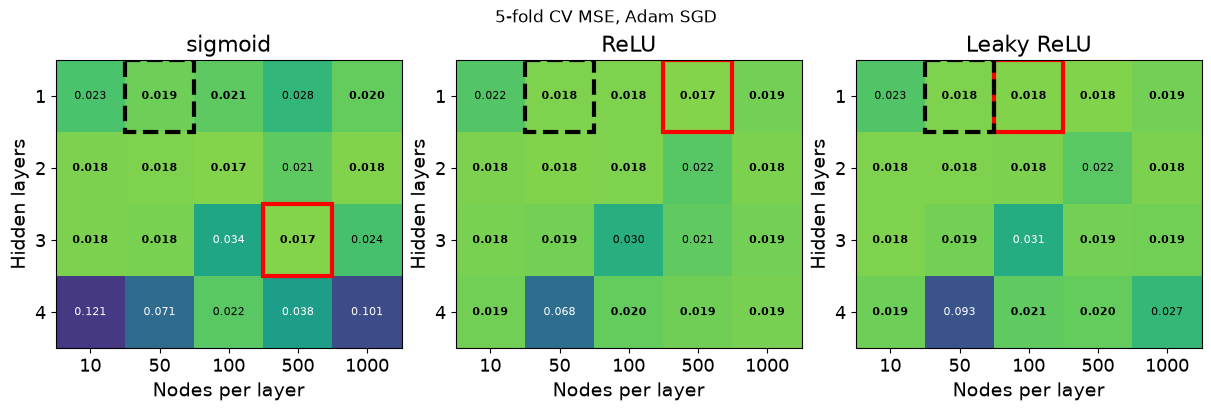

In [ ]:
#Same figure as above
fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
for ax, name in zip(axes, ["sigmoid", "ReLU", "Leaky ReLU"]):

    heatmap_nopen(ax, grid_layernodes[name], nlayers, [n for n in nodes], name, r"Hidden layers",r"Nodes per layer", grid_se=grid_se[name])
    ax.add_patch(plt.Rectangle((1 - 0.5, 0 - 0.5), 1, 1, fill=False, edgecolor="black", lw=3, linestyle="--"))   # choice of parameters due to 1se rule

fig.suptitle("5-fold CV MSE, Adam SGD")
#plt.savefig("./figures/partc_nlayers_nodes.png", dpi=500)
plt.show()


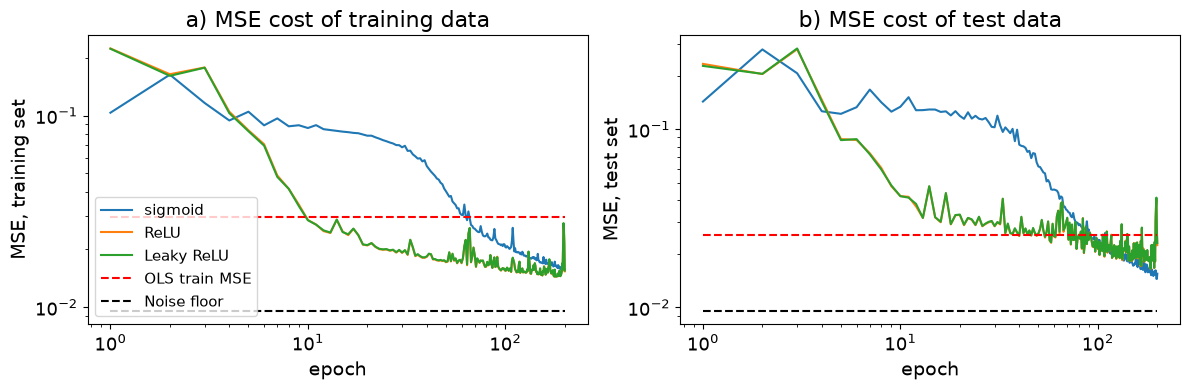

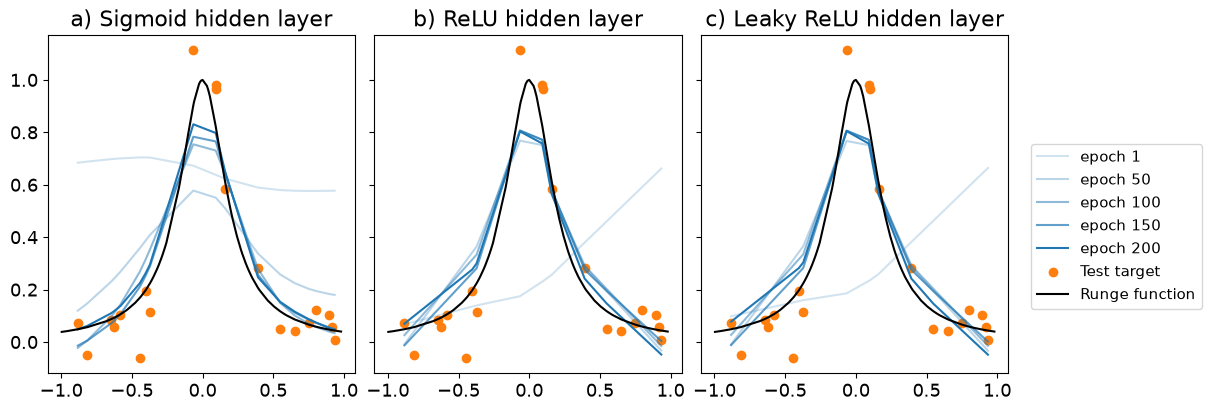

In [ ]:
#doing the training with the best parameters found above, with 1 hidden layer and 50 nodes (based on the 1 standard error rule)

#sigmoid as hidden layer
layers0, activation_funcs, activation_ders = setup_NN(x_tr.shape, y_tr.shape, design_hidden=[50], activation_funcs=sigmoid, activation_ders=sigmoid_der, activation_output=identity, activation_output_der=identity_der)
layers_sig, hist_sig,prediction_sig = train(layers0, x_tr, y_tr, x_te, y_te, step="adam",act=activation_funcs,act_der=activation_ders, gamma=0.005,  epochs=200, batch_size=15)


#ReLU as hidden layer
layers0, activation_funcs, activation_ders = setup_NN(x_tr.shape, y_tr.shape, design_hidden=[50], activation_funcs=ReLU, activation_ders=ReLU_der, activation_output=identity, activation_output_der=identity_der)
layers_relu, hist_relu,prediction_relu = train(layers0, x_tr, y_tr, x_te, y_te, step="adam",act=activation_funcs,act_der=activation_ders, gamma=0.005,  epochs=200, batch_size=15)


#Leaky ReLU as hidden layer
layers0, activation_funcs, activation_ders = setup_NN(x_tr.shape, y_tr.shape, design_hidden=[50], activation_funcs=leaky_ReLU, activation_ders=leaky_ReLU_der, activation_output=identity, activation_output_der=identity_der)
layers_lrelu, hist_lrelu,prediction_lrelu = train(layers0, x_tr, y_tr, x_te, y_te, step="adam",act=activation_funcs,act_der=activation_ders, gamma=0.005,  epochs=200, batch_size=15)


#plotting the results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.semilogy(hist_sig[:, 0], hist_sig[:, 1], label="sigmoid")
ax1.semilogy(hist_relu[:, 0], hist_relu[:, 1], label="ReLU")
ax1.semilogy(hist_lrelu[:, 0], hist_lrelu[:, 1], label="Leaky ReLU")
ax1.hlines(MSE(OLS_regression(x_tr, y_tr),y_tr), xmin=hist_sig[0, 0], xmax=hist_sig[-1, 0], colors='r', linestyles='dashed', label="OLS train MSE")
ax1.hlines(noise_floor, xmin=hist_sig[0, 0], xmax=hist_sig[-1, 0], colors='k', linestyles='dashed', label="Noise floor")

ax1.set_xlabel("epoch",fontsize=label_fontsize); ax1.set_ylabel("MSE, training set",fontsize=label_fontsize); ax1.set_xscale("log"); ax1.set_yscale("log"); ax1.legend(fontsize=legend_fontsize)
ax1.set_title("a) MSE cost of training data",fontsize=title_fontsize)
ax1.tick_params(axis='both', which='both', labelsize=tick_fontsize)
ax2.semilogy(hist_sig[:, 0], hist_sig[:, 2])
ax2.semilogy(hist_relu[:, 0], hist_relu[:, 2])
ax2.semilogy(hist_lrelu[:, 0], hist_lrelu[:, 2])
ax2.hlines(MSE(OLS_regression(x_te, y_te),y_te), xmin=hist_sig[0, 0], xmax=hist_sig[-1, 0], colors='r', linestyles='dashed', label="OLS test MSE")
ax2.hlines(noise_floor, xmin=hist_sig[0, 0], xmax=hist_sig[-1, 0], colors='k', linestyles='dashed', label="Noise floor")
ax2.set_xlabel("epoch",fontsize=label_fontsize); ax2.set_ylabel("MSE, test set",fontsize=label_fontsize); ax2.set_xscale("log")
ax2.set_title("b) MSE cost of test data",fontsize=title_fontsize)
ax2.tick_params(axis='both', which='both', labelsize=tick_fontsize)
# fig.suptitle("Different hidden layer activation functions",fontsize=title_fontsize)
plt.tight_layout()
plt.savefig("./figures/NN_activation_comparison.png", dpi=500)
plt.show()



fig, ax = plt.subplots(1,3, figsize=(12, 4),sharey=True, constrained_layout=True)
ax[0].plot(x_te_raw[order], prediction_sig[1][order, 0],  label="epoch 1",color="tab:blue",alpha=0.2)
ax[0].plot(x_te_raw[order], prediction_sig[50][order, 0],  label="epoch 50",color="tab:blue",alpha=0.3)
ax[0].plot(x_te_raw[order], prediction_sig[100][order, 0],  label="epoch 100",color="tab:blue",alpha=0.5)
ax[0].plot(x_te_raw[order], prediction_sig[150][order, 0],  label="epoch 150",color="tab:blue",alpha=0.7)
ax[0].plot(x_te_raw[order], prediction_sig[-1][order, 0],  label="epoch 200",color="tab:blue",alpha=1)
ax[0].scatter(x_te_raw[order], y_te[order],  label="Test target",color="tab:orange",alpha=1)
ax[0].plot(x, runge(x), "k", label="Runge function")
ax[0].set_title("a) Sigmoid hidden layer",fontsize=title_fontsize)
ax[0].tick_params(axis='both', which='both', labelsize=tick_fontsize)

ax[1].plot(x_te_raw[order], prediction_relu[1][order, 0],  label="epoch 1",color="tab:blue",alpha=0.2)
ax[1].plot(x_te_raw[order], prediction_relu[50][order, 0],  label="epoch 50",color="tab:blue",alpha=0.3)
ax[1].plot(x_te_raw[order], prediction_relu[100][order, 0],  label="epoch 100",color="tab:blue",alpha=0.5)
ax[1].plot(x_te_raw[order], prediction_relu[150][order, 0],  label="epoch 150",color="tab:blue",alpha=0.7)
ax[1].plot(x_te_raw[order], prediction_relu[-1][order, 0],  label="epoch 200",color="tab:blue",alpha=1)
ax[1].scatter(x_te_raw[order], y_te[order],  label="Test target",color="tab:orange",alpha=1)
ax[1].tick_params(axis='both', which='both', labelsize=tick_fontsize)
ax[1].plot(x, runge(x), "k", label="Runge function")
ax[1].set_title("b) ReLU hidden layer",fontsize=title_fontsize)

ax[2].plot(x_te_raw[order], prediction_lrelu[1][order, 0],  label="epoch 1",color="tab:blue",alpha=0.2)
ax[2].plot(x_te_raw[order], prediction_lrelu[50][order, 0],  label="epoch 50",color="tab:blue",alpha=0.3)
ax[2].plot(x_te_raw[order], prediction_lrelu[100][order, 0],  label="epoch 100",color="tab:blue",alpha=0.5)
ax[2].plot(x_te_raw[order], prediction_lrelu[150][order, 0],  label="epoch 150",color="tab:blue",alpha=0.7)
ax[2].plot(x_te_raw[order], prediction_lrelu[-1][order, 0],  label="epoch 200",color="tab:blue",alpha=1)
ax[2].scatter(x_te_raw[order], y_te[order],  label="Test target",color="tab:orange",alpha=1)
ax[2].tick_params(axis='both', which='both', labelsize=tick_fontsize)
ax[2].plot(x, runge(x), "k", label="Runge function")
ax[2].set_title("c) Leaky ReLU hidden layer",fontsize=title_fontsize)
ax[2].legend(bbox_to_anchor=(1.05, 0.7),fontsize=legend_fontsize)
plt.savefig("./figures/predict_activation_comparison.png", dpi=500)
plt.show()


### Part d): Testing different norms

In [ ]:
# Your code for part d) here
###################################
# add the L1 / L2 penalties to the network code of part b)
###################################

# same data, split and scaling as in part b)
x_tr, x_te, y_tr, y_te = prepare_data(x, y)

# ---- The penalised cost function and its gradient -----------------------------------
#   L2:  C = MSE + lam * sum(W^2)    ->  dC/dW = dMSE/dW + 2 * lam * W
#   L1:  C = MSE + lam * sum(|W|)    ->  dC/dW = dMSE/dW + lam * sign(W)
# Same convention as Ridge/Lasso of project 1 (cost = (1/n)*||y - X theta||^2 + penalty).
# The penalty only changes the GRADIENT; the MSE we report is always the plain MSE.
# lam = 0 gives the unpenalised network (then it does not matter which norm is chosen).
def penalty_grad(layers, lam, norm):
    """Gradient of the penalty term, one (dW, db) pair per layer (same shapes as the layers)."""
    grads = []
    for W, b in layers:
        if norm == "l2":
            dW = 2.0 * lam * W
        elif norm == "l1":
            dW = lam * np.sign(W)
        else:
            raise ValueError("norm must be 'l2' or 'l1'")
        grads.append((dW, np.zeros_like(b))) # the biases are NOT penalised (as the intercept in Ridge/Lasso)
    return grads

def backprop_penalised(X, layers, act, y, act_der, lam, norm):
    """Back propagation from part b) (MSE only) + the gradient of the penalty."""
    grads = backpropagation_batch(X, layers, act, y, act_der) # <- unchanged code from part b)
    pen = penalty_grad(layers, lam, norm)
    return [(dW + pW, db + pb) for (dW, db), (pW, pb) in zip(grads, pen)]

# ---- Training loop: identical to train() of part b), except for the penalised gradient --
def train_penalised(layers, X, y, X_val, y_val, step, act, act_der, gamma, epochs,
                    lam, norm, batch_size=15, seed=2026):
    """Minibatch training. Returns the trained layers and a history of
    (epoch, training MSE, validation MSE); both are plain MSEs without the penalty."""
    rng = np.random.default_rng(seed)
    n = len(X)
    state, t, history = None, 0, []
    for epoch in range(1, epochs + 1):
        perm = rng.permutation(n) # new shuffle every epoch
        for start in range(0, n, batch_size):
            idx = perm[start:start + batch_size]
            grads = backprop_penalised(X[idx], layers, act, y[idx], act_der, lam, norm)
            t += 1
            layers, state = optimiser_step(step, layers, grads, gamma, t, state) # plain/rmsprop/adam
        history.append((epoch, float(cost_batch(layers, X, act, y)),
                               float(cost_batch(layers, X_val, act, y_val))))
    return layers, np.array(history)

def build_net(hidden, seed=2026):
    """Sigmoid hidden layers + linear output (part b/c); weights ~ N(0, 1/n_in), biases = 0."""
    layers = init_layers([1] + hidden + [1], seed)
    act = [ReLU] * len(hidden) + [identity]
    der = [ReLU_der] * len(hidden) + [identity_der]
    # act = [sigmoid] * len(hidden) + [identity]
    # der = [sigmoid_der] * len(hidden) + [identity_der]
    return layers, act, der


# Check: compare with automatic differentiation in JAX, as in part b)
def penalised_cost_jax(layers, X, y, act, lam, norm):
    """Same cost as penalised_cost, but written with jnp so that JAX can differentiate it."""
    pen = 0.0
    for W, b in layers:
        pen = pen + (lam * jnp.sum(W**2) if norm == "l2" else lam * jnp.sum(jnp.abs(W)))
    return cost_batch(layers, X, act, y) + pen

def check_gradient_jax(norm, lam=1e-2):
    """Largest difference between backprop and jax.grad of the full penalised cost."""
    layers, act, der = build_net([5, 5], seed=1)
    g_hand = backprop_penalised(x_tr, layers, act, y_tr, der, lam, norm)
    # jax.grad differentiates with respect to the list of (W, b) pairs and returns the same structure
    g_jax = jax.grad(lambda L: penalised_cost_jax(L, x_tr, y_tr, act, lam, norm))(layers)
    return max(max(np.max(np.abs(dW - np.asarray(dW_j))), np.max(np.abs(db - np.asarray(db_j))))
               for (dW, db), (dW_j, db_j) in zip(g_hand, g_jax))

for norm in ["l2", "l1"]:
    print(f"norm = {norm}: max |JAX - backprop| = {check_gradient_jax(norm):.1e}")


norm = l2: max |JAX - backprop| = 1.4e-17
norm = l1: max |JAX - backprop| = 5.6e-17


In [ ]:
###################################
# the benchmarks from project 1 (OLS, Ridge, Lasso on polynomial features)
###################################

import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # remove annoying warnings

# The same 80/20 split as the network, but with the raw x (the polynomial pipeline scales itself)
x_tr_raw, x_te_raw, y_tr_raw, y_te_raw = train_test_split(x, y, test_size=0.2, random_state=2026)
assert np.allclose(y_tr_raw, y_tr.ravel()) # check: same training points as the network

def fit_poly(kind, degree, lam, x_fit, y_fit):
    """Polynomial regression as in project 1 (PolynomialFeatures -> StandardScaler -> model).
    lam is defined as for the network:  cost = MSE + lam*sum(theta^2)  or  MSE + lam*sum(|theta|).
    scikit-learn uses other normalisations, so the conversion is
        Ridge:  ||y - X theta||^2 + alpha ||theta||^2        ->  alpha = n * lam
        Lasso:  ||y - X theta||^2 / (2n) + alpha |theta|_1    ->  alpha = lam / 2   (as in project 1)"""
    if kind == "OLS":
        reg = LinearRegression()
    elif kind == "Ridge":
        reg = Ridge(alpha=len(x_fit) * lam)
    else:
        reg = Lasso(alpha=lam / 2.0, max_iter=100000)
    model = make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), reg)
    return model.fit(x_fit.reshape(-1, 1), y_fit)

# 5-fold cross-validation on the TRAINING data only (the test set is not touched here).
# NB: these are the same folds that are used for the network below.
kfold = KFold(5, shuffle=True, random_state=2026)
def poly_cv(kind, degree, lam):
    errs = []
    for tr, va in kfold.split(x_tr_raw):
        m = fit_poly(kind, degree, lam, x_tr_raw[tr], y_tr_raw[tr])
        errs.append(np.mean((y_tr_raw[va] - m.predict(x_tr_raw[va].reshape(-1, 1))) ** 2))
    return np.mean(errs)

degrees = list(range(1, 13)) # polynomial degrees as in project 1
poly_lams = np.logspace(-6, 0, 13) # lambda grid for Ridge and Lasso

baseline = {} # kind -> (cv mse, degree, lambda)
for kind in ["OLS", "Ridge", "Lasso"]:
    best = (np.inf, None, None)
    for d in degrees:
        for lam in ([0.0] if kind == "OLS" else poly_lams):
            err = poly_cv(kind, d, lam)
            if err < best[0]:
                best = (err, d, lam)
    baseline[kind] = best
    print(f"{kind:5s}: best CV-MSE = {best[0]:.4f} at degree {best[1]}" +
          ("" if kind == "OLS" else f", lambda = {best[2]:.1e}"))

# Refit the three winners on all 80 training points and evaluate on the 20 test points
baseline_models = {}
for kind, (cv_err, d, lam) in baseline.items():
    m = fit_poly(kind, d, lam, x_tr_raw, y_tr_raw)
    baseline_models[kind] = m
    train_mse = np.mean((y_tr_raw - m.predict(x_tr_raw.reshape(-1, 1))) ** 2)
    test_mse = np.mean((y_te_raw - m.predict(x_te_raw.reshape(-1, 1))) ** 2)
    baseline[kind] = (cv_err, d, lam, train_mse, test_mse)
    print(f"{kind:5s}: train MSE = {train_mse:.4f}, test MSE = {test_mse:.4f}")

# The best any model can do on these 20 test points is the noise in them:
noise_floor = np.mean((y_te_raw - runge(x_te_raw)) ** 2)
print(f"noise level on the test points (true Runge function vs data): {noise_floor:.4f}  (sigma^2 = {sigma**2})")


OLS  : best CV-MSE = 0.0266 at degree 8
Ridge: best CV-MSE = 0.0226 at degree 12, lambda = 3.2e-06
Lasso: best CV-MSE = 0.0259 at degree 9, lambda = 1.0e-04
OLS  : train MSE = 0.0173, test MSE = 0.0187
Ridge: train MSE = 0.0156, test MSE = 0.0221
Lasso: train MSE = 0.0172, test MSE = 0.0184
noise level on the test points (true Runge function vs data): 0.0096  (sigma^2 = 0.010000000000000002)


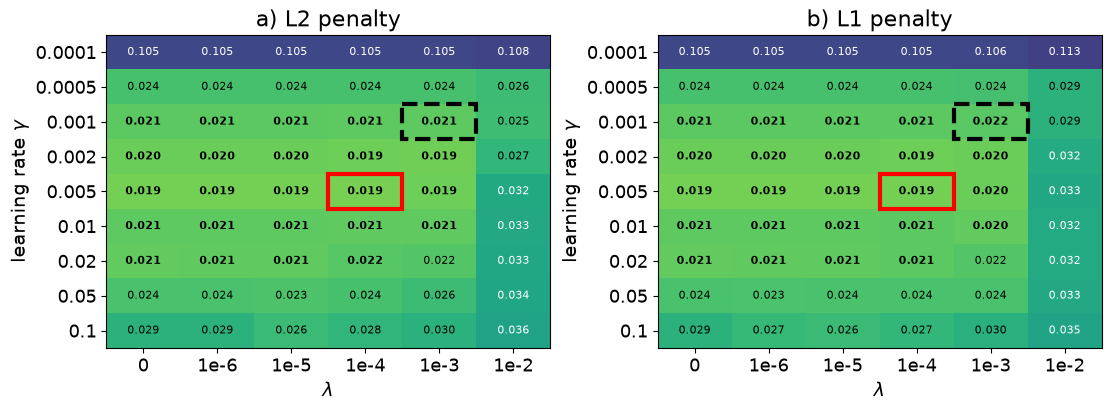

learning rate used from here on: gamma = 0.005


In [ ]:
###################################
# lambda x learning rate for L2 and L1 (Adam, 1 hidden layer of 50 ReLU nodes)
###################################
def cv_mse(hidden, gamma, lam, norm, k=5, epochs=200):
    """5-fold CV MSE on the training data for one network setting (mean and standard error over the folds).
    The validation MSE of a fold is averaged over the last 10 epochs, to remove jittering."""
    scores = []
    for tr, va in KFold(k, shuffle=True, random_state=2026).split(x_tr):
        layers, act, der = build_net(hidden)
        _, hist = train_penalised(layers, x_tr[tr], y_tr[tr], x_tr[va], y_tr[va],
                                  "adam", act, der, gamma, epochs, lam, norm)
        scores.append(hist[-10:, 2].mean())
    return float(np.mean(scores)), float(np.std(scores)) / np.sqrt(len(scores))   # mean and standard error, as cv_mse_nopen

def lam_label(l):
    return "0" if l == 0 else f"1e{int(round(np.log10(l)))}"

lam_grid = [0.0, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2] # lambda = 0 is the unregularised network
gamma_grid = [0.0001, 0.0005, 0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1] # learning rates for Adam
lam_labels = [lam_label(l) for l in lam_grid]
norms = ["l2", "l1"]

grid_gl, grid_gl_se = {}, {} # norm -> (len(gamma_grid) x len(lam_grid)) arrays: CV MSE and its standard error
for norm in norms:
    res = np.array([[cv_mse([50], g, lam, norm) for lam in lam_grid] for g in gamma_grid]) # last axis: (mean, se)
    grid_gl[norm], grid_gl_se[norm] = res[..., 0], res[..., 1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, norm, name in zip(axes, norms, ["a) L2 penalty", "b) L1 penalty"]):
    heatmap_nopen(ax, grid_gl[norm], gamma_grid, lam_labels, name, r"learning rate $\gamma$", r"$\lambda$", grid_se=grid_gl_se[norm])
    # black dashed frame to choose best according to 1 se rule 
    ax.add_patch(plt.Rectangle((lam_grid.index(1e-3) - 0.5, gamma_grid.index(0.001) - 0.5), 1, 1, fill=False, edgecolor="black", lw=3, linestyle="--", clip_on=False))
# fig.suptitle("5-fold CV MSE, Adam, 1 hidden layer with 50 ReLU nodes (red = lowest, black = 1-se rule, bold = within 1 se)")
plt.savefig("./figures/partd_lambda_gamma.png", dpi=500)
plt.show()

# One learning rate for the rest of part d): the best one over both grids (all lambda)
best_gamma = min(((grid_gl[n][i, j], gamma_grid[i]) for n in norms
                  for i in range(len(gamma_grid)) for j in range(len(lam_grid))))[1]
print("learning rate used from here on: gamma =", best_gamma)


In [ ]:
###################################
# lambda x network architecture (the learning rate is kept at its best value)
###################################
architectures = [[10], [50], [100], [500], [50, 50], [100, 100], [50, 50, 50], [100, 100, 100], [50, 50, 50, 50]]
arch_labels = [f"{len(a)}x{a[0]}" for a in architectures] # e.g. "2x50" = 2 hidden layers, 50 nodes

grid_al, grid_al_se = {}, {} # norm -> (architectures x lambdas): CV MSE and its standard error
for norm in norms:
    res = np.array([[cv_mse(a, best_gamma, lam, norm) for lam in lam_grid] for a in architectures])
    grid_al[norm], grid_al_se[norm] = res[..., 0], res[..., 1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
for ax, norm, name in zip(axes, norms, ["a) L2 penalty", "b) L1 penalty"]):
    heatmap_nopen(ax, grid_al[norm], arch_labels, lam_labels, name, "hidden layers x nodes", r"$\lambda$", grid_se=grid_al_se[norm])
    # black dashed frame = the cell you choose (1-se rule): give its architecture label and its lambda
    ax.add_patch(plt.Rectangle((lam_grid.index(1e-3) - 0.5, arch_labels.index("1x50") - 0.5), 1, 1, fill=False, edgecolor="black", lw=3, linestyle="--", clip_on=False))
# fig.suptitle(rf"5-fold CV MSE, Adam, $\gamma$ = {best_gamma}, ReLU (red = lowest, black = 1-se rule, bold = within 1 se)")
plt.savefig("./figures/partd_lambda_architecture.png", dpi=500)
plt.show()

# Best settings: with the penalty (lambda > 0) for each norm, and without (lambda = 0) as reference
choice = {} # name -> (hidden, lambda, norm, cv mse)
for norm in norms:
    sub = grid_al[norm][:, 1:] # drop the lambda = 0 column
    i, j = np.unravel_index(np.argmin(sub), sub.shape)
    choice[norm] = (architectures[i], lam_grid[j + 1], norm, sub[i, j])
i0 = np.argmin(grid_al["l2"][:, 0]) # column lambda = 0 (same for L1 and L2)
choice["unpenalised"] = (architectures[i0], 0.0, "l2", grid_al["l2"][i0, 0]) # lambda = 0: the norm does not matter
for name, (hid, lam, norm, err) in choice.items():
    print(f"best {name:4s}: hidden layers {hid}, lambda = {lam:g}, CV MSE = {err:.4f}")

# Does the penalty help? Compare, for every architecture, lambda = 0 with the best lambda > 0
print("\narchitecture   CV MSE (lambda=0)   best L2: CV MSE (lambda)    best L1: CV MSE (lambda)")
for i, lab in enumerate(arch_labels):
    line = f"{lab:12s}   {grid_al['l2'][i, 0]:.4f}      "
    for norm in norms:
        j = np.argmin(grid_al[norm][i, 1:]) + 1
        line += f"     {grid_al[norm][i, j]:.4f} ({lam_grid[j]:.0e})   "
    print(line)


KeyboardInterrupt: 


model                          settings                           train MSE  test MSE
OLS (polynomial)               degree 8                              0.0173    0.0187
Ridge (polynomial)             degree 12, lambda=3e-06               0.0156    0.0221
Lasso (polynomial)             degree 9, lambda=1e-04                0.0172    0.0184
NN, no penalty                 4x50, lambda=0, gamma=0.001           0.0130    0.0124
NN + L2                        3x50, lambda=0.001, gamma=0.001       0.0146    0.0184
NN + L1                        4x50, lambda=0.0001, gamma=0.001      0.0136    0.0126
NN 1x50, no penalty            1x50, lambda=0, gamma=0.001           0.0172    0.0261
NN 1x50 + L2                   1x50, lambda=0.001, gamma=0.001       0.0172    0.0257
NN 1x50 + L1                   1x50, lambda=0.001, gamma=0.001       0.0175    0.0263
noise level of test points                                                     0.0096


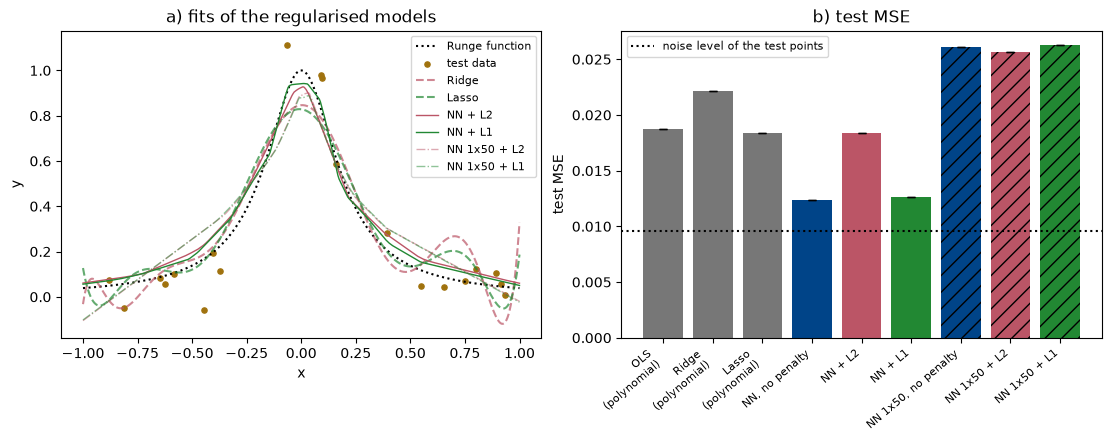

In [ ]:
###################################
# final training, comparison with OLS / Ridge / Lasso
###################################
seeds = [2026]
# seeds = range(10) #for a mean +- spread over several runs (10 times slower)

# 1x50 network chosen with the 1-se rule, without penalty and with L2 / L1 (set your lambdas)
choice["unpenalised_1se"] = ([50], 0.0, "l2", None)
choice["l2_1se"] = ([50], 1e-3, "l2", None)
choice["l1_1se"] = ([50], 1e-3, "l1", None)

x_mean, x_std = x_tr_raw.mean(), x_tr_raw.std() # the same scaling as in prepare_data
xx = np.linspace(-1, 1, 400) # dense grid for plotting the fits
xx_std = ((xx - x_mean) / x_std).reshape(-1, 1)

final = {} # name -> dict with the results
for name, (hid, lam, norm, _) in choice.items():
    tr_err, te_err = [], []
    for seed in seeds:
        layers, act, der = build_net(hid, seed=seed)
        if '1se' in name:
            best_gamma = 0.001
        else:
            best_gamma = 0.005
        layers, hist = train_penalised(layers, x_tr, y_tr, x_te, y_te, "adam", act, der,
                                       best_gamma, 200, lam, norm, seed=seed)
        tr_err.append(hist[-1, 1]) # MSE after the last epoch
        te_err.append(hist[-1, 2])
        if seed == seeds[0]: # keep the fit of the first run for the plot
            curve = feed_forward_batch(xx_std, layers, act)[:, 0]
    final[name] = dict(train=np.mean(tr_err), test=np.mean(te_err), test_std=np.std(te_err), curve=curve)

### Table
print(f"\n{'model':30s} {'settings':34s} {'train MSE':>9s} {'test MSE':>9s}")
rows = []
for kind in ["OLS", "Ridge", "Lasso"]:
    cv_err, d, lam, tr_m, te_m = baseline[kind]
    s = f"degree {d}" + ("" if kind == "OLS" else f", lambda={lam:.0e}")
    rows.append((kind + " (polynomial)", s, tr_m, te_m, 0.0))
for name, label in [("unpenalised", "NN, no penalty"), ("l2", "NN + L2"), ("l1", "NN + L1"),
                    ("unpenalised_1se", "NN 1x50, no penalty"), ("l2_1se", "NN 1x50 + L2"), ("l1_1se", "NN 1x50 + L1")]: # NEW: last three
    hid, lam, norm, _ = choice[name]
    s = f"{len(hid)}x{hid[0]}, lambda={lam:g}, gamma={best_gamma}"
    rows.append((label, s, final[name]["train"], final[name]["test"], final[name]["test_std"]))
for r in rows:
    spread = f" +- {r[4]:.4f}" if r[4] > 0 else "" # the spread only exists with several seeds
    print(f"{r[0]:30s} {r[1]:34s} {r[2]:9.4f} {r[3]:9.4f}{spread}")
print(f"{'noise level of test points':30s} {'':34s} {'':9s} {noise_floor:9.4f}")

### Figure: (a) fits of the regularised models, (b) test MSE of all models
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3), constrained_layout=True)

ax[0].plot(xx, runge(xx), "k:", label="Runge function")
ax[0].scatter(x_te_raw, y_te_raw, s=14, color="#A0720E", label="test data")
ax[0].plot(xx, baseline_models["Ridge"].predict(xx.reshape(-1, 1)), color=RED, alpha=0.7, ls="--", label="Ridge")
ax[0].plot(xx, baseline_models["Lasso"].predict(xx.reshape(-1, 1)), color=GREEN, alpha=0.7, ls="--", label="Lasso")
ax[0].plot(xx, final["l2"]["curve"], color=RED, ls="-", lw=1, alpha=1, label="NN + L2")
ax[0].plot(xx, final["l1"]["curve"], color=GREEN, ls="-", lw=1, alpha=1, label="NN + L1")
ax[0].plot(xx, final["l2_1se"]["curve"], color=RED, ls="-.", lw=1, alpha=0.5, label="NN 1x50 + L2")
ax[0].plot(xx, final["l1_1se"]["curve"], color=GREEN, ls="-.", lw=1, alpha=0.5, label="NN 1x50 + L1")
ax[0].set_xlabel("x"); ax[0].set_ylabel("y"); ax[0].legend(fontsize=8)
ax[0].set_title("a) fits of the regularised models")

labels = [r[0] for r in rows]
bars = ax[1].bar(range(len(rows)), [r[3] for r in rows], yerr=[r[4] for r in rows],
                 color=[GREY, GREY, GREY, BLUE, RED, GREEN, BLUE, RED, GREEN], capsize=3) 
for b in bars[6:]:
    b.set_hatch("//") # hatched = the 1x50 network chosen with the 1-se rule
ax[1].axhline(noise_floor, color="k", ls=":", label="noise level of the test points")
ax[1].set_xticks(range(len(rows)))
ax[1].set_xticklabels([l.replace(" (polynomial)", "\n(polynomial)") for l in labels], rotation=40, ha="right", fontsize=8)
ax[1].set_ylabel("test MSE"); ax[1].legend(fontsize=8)
ax[1].set_title("b) test MSE")
plt.savefig("./figures/partd_comparison.png", dpi=500)
plt.show()

### Part e): Classification analysis using neural networks

In [ ]:
x_train = x_train.reshape(len(x_train), -1) / 255.0
x_test = x_test.reshape(len(x_test), -1) / 255.0

In [ ]:
from sklearn.linear_model import LogisticRegression
# Initialize the model (multinomial logistic regression with the saga solver)
model = LogisticRegression(solver='saga', max_iter=1000, random_state=42)
# Train the model
model.fit(x_train, y_train)
from sklearn.metrics import accuracy_score
# Make predictions on the test set
y_pred = model.predict(x_test)
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}")

In [ ]:
# Your code for part e) here
with np.load("mnist.npz") as data:
    X_train = data["x_train"]
    y_train = data["y_train"]
    X_test = data["x_test"]
    y_test = data["y_test"]

# Flatten each 28x28 image into 784 numbers
X_train = X_train.reshape(X_train.shape[0], -1)
X_test = X_test.reshape(X_test.shape[0], -1)

# Scale pixel values from 0-255 to 0-1
X_train = X_train / 255.0
X_test = X_test / 255.0

In [ ]:
def one_hot(y, n_classes=10):
    """Convert digit labels into ten-column answer vectors."""
    return np.eye(n_classes)[y]


def cross_entropy(predict, target):
    """Measure how far the predictions are from the correct answers."""
    eps = 1e-15
    predict = jnp.clip(predict, eps, 1.0 - eps)
    return -jnp.mean(jnp.sum(target * jnp.log(predict), axis=1))


def output_error_softmax_ce(predict, target):
    """Output-layer error for softmax combined with cross-entropy."""
    return predict - target


def accuracy(predict, y_true):
    """Calculate the proportion of images classified correctly."""
    predicted_digits = np.argmax(np.asarray(predict), axis=1)
    return np.mean(predicted_digits == y_true)



In [ ]:
def backpropagation_batch(inputs, layers, activation_funcs,
                          targets, activation_ders):

    # Make predictions and save information from each layer
    layer_inputs, zs, predict = feed_forward_saver_batch(
        inputs, layers, activation_funcs
    )

    n = inputs.shape[0]

    # Calculate the error at the output layer
    dC_dz = output_error_softmax_ce(predict, targets)

    gradients = [None] * len(layers)

    # Work backwards through the network
    for l in reversed(range(len(layers))):

        layer_input = layer_inputs[l]
        W, b = layers[l]

        # Calculate how much the weights and biases should change
        dC_dW = layer_input.T @ dC_dz / n
        dC_db = np.sum(dC_dz, axis=0) / n

        gradients[l] = (dC_dW, dC_db)

        # Pass the error backwards to the previous layer
        if l > 0:
            dC_da = dC_dz @ W.T
            dC_dz = dC_da * activation_ders[l - 1](zs[l - 1])

    return gradients

In [ ]:
def train_classifier(
    layers,
    X_train,
    Y_train,
    X_val,
    y_val,
    activation_funcs,
    activation_ders,
    gamma=0.01,
    epochs=20,
    batch_size=128,
    method="adam",
    seed=2026
):
    rng = np.random.default_rng(seed)
    state = None
    t = 0

    train_losses = []
    val_losses = []
    val_accuracies = []

    n = X_train.shape[0]

    for epoch in range(epochs):

        # Shuffle the training images
        indices = rng.permutation(n)
        X_shuffled = X_train[indices]
        Y_shuffled = Y_train[indices]

        # Divide the training data into smaller batches
        for start in range(0, n, batch_size):
            end = start + batch_size

            X_batch = X_shuffled[start:end]
            Y_batch = Y_shuffled[start:end]

            # Work out how the network should improve
            grads = backpropagation_batch(
                X_batch,
                layers,
                activation_funcs,
                Y_batch,
                activation_ders
            )

            # Update the network's weights
            t += 1
            layers, state = optimiser_step(
                method, layers, grads, gamma, t, state
            )

        # Check performance after each epoch
        train_predict = feed_forward_batch(
            X_train, layers, activation_funcs
        )
        val_predict = feed_forward_batch(
            X_val, layers, activation_funcs
        )

        train_loss = float(cross_entropy(train_predict, Y_train))
        val_loss = float(cross_entropy(val_predict, one_hot(y_val)))

        val_accuracy = accuracy(val_predict, y_val)

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Training loss: {train_loss:.4f} | "
            f"Validation loss: {val_loss:.4f} | "
            f"Validation accuracy: {val_accuracy:.4f}"
        )

    history = {
        "train_loss": train_losses,
        "val_loss": val_losses,
        "val_accuracy": val_accuracies
    }

    return layers, history

In [ ]:
# Split the original training data into training and validation sets
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=2026,
    stratify=y_train
)

# Convert the training labels into one-hot format
Y_fit = one_hot(y_fit)

print("Training images:", X_fit.shape)
print("Validation images:", X_val.shape)
print("Training labels:", Y_fit.shape)

In [ ]:
#initialise the weights and biases
def init_layers(sizes, seed):
    rng = np.random.default_rng(seed)
    return [(rng.standard_normal((n_in, n_out)) / np.sqrt(n_in), np.zeros(n_out)) #weights are initialised with a normal distribution with mean 0 and variance 1/n_in, biases are initialised to 0
            for n_in, n_out in zip(sizes[:-1], sizes[1:])]
    
    # Define the network architecture
layers = init_layers([784, 32, 10], seed=2026)

# Choose activation functions
activation_funcs = [ReLU, softmax]
activation_ders = [ReLU_der]

# Train the network
layers, history = train_classifier(
    layers,
    X_fit,
    Y_fit,
    X_val,
    y_val,
    activation_funcs,
    activation_ders,
    gamma=0.001,
    epochs=15,
    batch_size=128,
    method="adam"
)

In [ ]:
# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history["train_loss"], label="Training loss")
plt.plot(history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Training and validation loss")
plt.legend()
plt.grid()
plt.show()


# Plot validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Validation accuracy during training")
plt.legend()
plt.grid()
plt.show()

In [ ]:
# Make predictions on the official test images
test_predict = feed_forward_batch(
    X_test,
    layers,
    activation_funcs
)

# Calculate final test accuracy
test_accuracy = accuracy(test_predict, y_test)

print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test accuracy in percent: {test_accuracy * 100:.2f}%")

In [ ]:
#So up until this point it's the first bit of part e, now i will look at diff models and hyperparameters
# First establishing logistic regression baseline

# Create a network with no hidden layers
logistic_layers = init_layers([784, 10], seed=2026)

# Only one activation function: softmax at the output
logistic_activation_funcs = [softmax]

# Train the logistic regression model
logistic_layers, logistic_history = train_classifier(
    logistic_layers,
    X_fit,
    Y_fit,
    X_val,
    y_val,
    logistic_activation_funcs,
    [],                  # No hidden layers, so no hidden activation derivatives
    gamma=0.001,
    epochs=15,
    batch_size=128,
    method="adam"
)

In [ ]:
# Get the final validation accuracy of each model
logistic_accuracy = logistic_history["val_accuracy"][-1]
nn_accuracy = history["val_accuracy"][-1]

print(f"Logistic regression validation accuracy: {logistic_accuracy:.4f}")
print(f"Neural network validation accuracy:     {nn_accuracy:.4f}")

print(f"\nLogistic regression: {logistic_accuracy * 100:.2f}%")
print(f"Neural network:      {nn_accuracy * 100:.2f}%")

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    logistic_history["val_accuracy"],
    label="Logistic regression"
)

plt.plot(
    history["val_accuracy"],
    label="Neural network (32 hidden neurons)"
)

plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Logistic regression vs neural network")
plt.legend()
plt.grid()
plt.show()

In [ ]:
# Experimenting with architectures in order to compare no hidden layer vs one hidden layer vs multiple hidden layers
architectures = {
    "32 neurons": [784, 32, 10],
    "64 neurons": [784, 64, 10],
    "128 neurons": [784, 128, 10],
    "Two hidden layers": [784, 64, 32, 10]
}

architecture_results = {}

for name, sizes in architectures.items():

    print(f"\nTraining: {name}")

    layers_new = init_layers(sizes, seed=2026)

    # ReLU for every hidden layer, softmax for the output
    activation_funcs_new = [ReLU] * (len(sizes) - 2) + [softmax]

    # Derivatives are only needed for hidden layers
    activation_ders_new = [ReLU_der] * (len(sizes) - 2)

    trained_layers, history_new = train_classifier(
        layers_new,
        X_fit, Y_fit,
        X_val, y_val,
        activation_funcs_new,
        activation_ders_new,
        gamma=0.001,
        epochs=15,
        batch_size=128,
        method="adam",
        seed=2026
    )

    architecture_results[name] = {
        "layers": trained_layers,
        "history": history_new,
        "activation_funcs": activation_funcs_new,
        "activation_ders": activation_ders_new
    }

In [ ]:
print(f"{'Model':<25} {'Best validation accuracy':>25}")

# Existing logistic regression
print(
    f"{'Logistic regression':<25}"
    f"{max(logistic_history['val_accuracy']):>25.4f}"
)

for name, result in architecture_results.items():

    best_accuracy = max(result["history"]["val_accuracy"])

    print(f"{name:<25}{best_accuracy:>25.4f}")

In [ ]:
label_fontsize = 14
title_fontsize=16
tick_fontsize=13
legend_fontsize=11


plt.figure(figsize=(12, 6))

# Logistic regression
plt.plot(
    np.arange(1, len(logistic_history["val_accuracy"]) + 1),
    logistic_history["val_accuracy"],
    label="Logistic regression",
    linewidth=2
)

# All neural network architectures
for name, result in architecture_results.items():

    accuracy_values = result["history"]["val_accuracy"]

    plt.plot(
        np.arange(1, len(accuracy_values) + 1),
        accuracy_values,
        label=name,
        linewidth=2
    )

plt.xlabel("Epoch",fontsize=label_fontsize)
plt.ylabel("Validation accuracy",fontsize=label_fontsize)
plt.title("Validation accuracy for different network architectures",fontsize=title_fontsize)


plt.xticks(range(1, 16))
plt.ylim(0.90, 1.00)
plt.tick_params(axis="both",which="both",labelsize=tick_fontsize)

plt.legend(loc="lower right",fontsize=legend_fontsize)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("Validation accuracy for different network architectures.pdf", format="pdf", bbox_inches="tight")
plt.show()



In [ ]:
# Asctivation comparison section

activation_experiments = {
    "ReLU": (ReLU, ReLU_der),
    "Leaky ReLU": (leaky_ReLU, leaky_ReLU_der),
    "Sigmoid": (sigmoid, sigmoid_der)
}

activation_results = {}

for name, (activation, derivative) in activation_experiments.items():

    print(f"\nTraining with {name}")

    # Initialise a fresh network with the same architecture
    layers_new = init_layers([784, 128, 10], seed=2026)

    # Hidden layer uses the chosen activation.
    # Output layer always uses softmax.
    activation_funcs_new = [activation, softmax]
    activation_ders_new = [derivative]

    trained_layers, history_new = train_classifier(
        layers_new,
        X_fit, Y_fit,
        X_val, y_val,
        activation_funcs_new,
        activation_ders_new,
        gamma=0.001,
        epochs=15,
        batch_size=128,
        method="adam",
        seed=2026
    )

    activation_results[name] = {
        "layers": trained_layers,
        "history": history_new,
        "activation_funcs": activation_funcs_new,
        "activation_ders": activation_ders_new
    }

In [ ]:
print("Activation function comparison")
print("--------------------------------")

print(f"{'Activation':<20} {'Best val. accuracy':>20}")

for name, result in activation_results.items():

    best_accuracy = max(result["history"]["val_accuracy"])

    print(f"{name:<20} {best_accuracy:>20.4f}")

In [ ]:
plt.figure(figsize=(9, 5))

for name, result in activation_results.items():

    values = result["history"]["val_accuracy"]

    plt.plot(
        range(1, len(values) + 1),
        values,
        label=name,
        linewidth=2
    )

plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Effect of activation function on classification accuracy")
plt.xticks(range(1, 16))
plt.ylim(0.90, 1.00)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(9, 5))

for name, result in activation_results.items():

    values = result["history"]["val_loss"]

    plt.plot(
        range(1, len(values) + 1),
        values,
        label=name,
        linewidth=2
    )

plt.xlabel("Epoch")
plt.ylabel("Validation cross-entropy loss")
plt.title("Validation loss for different activation functions")
plt.xticks(range(1, 16))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import KFold

def cv_classifier(gamma, k=5, epochs=15, batch_size=128):
    """
    5-fold cross-validation for one learning rate.

    Returns:
    - Mean cross-validation cross-entropy
    - Standard error of cross-validation cross-entropy
    - Mean cross-validation accuracy
    """

    scores = []
    accuracies = []

    kf = KFold(
        n_splits=k,
        shuffle=True,
        random_state=2026
    )

    for tr, va in kf.split(X_fit):

        # Divide the data into training and validation sets
        X_fold_train = X_fit[tr]
        y_fold_train = y_fit[tr]

        X_fold_val = X_fit[va]
        y_fold_val = y_fit[va]

        # Convert training labels to one-hot encoding
        Y_fold_train = one_hot(y_fold_train)

        # Initialise a new neural network
        layers = init_layers([784, 128, 10], seed=2026)

        activation_funcs = [ReLU, softmax]
        activation_ders = [ReLU_der]

        # Train the neural network
        trained_layers, history = train_classifier(
            layers,
            X_fold_train,
            Y_fold_train,
            X_fold_val,
            y_fold_val,
            activation_funcs,
            activation_ders,
            gamma=gamma,
            epochs=epochs,
            batch_size=batch_size,
            method="adam",
            seed=2026
        )

        # Average the validation results over the final 3 epochs
        scores.append(np.mean(history["val_loss"][-3:]))
        accuracies.append(np.mean(history["val_accuracy"][-3:]))

    scores = np.array(scores)
    accuracies = np.array(accuracies)

    # Calculate mean cross-validation loss and its standard error
    mean_loss = np.mean(scores)
    se_loss = np.std(scores, ddof=1) / np.sqrt(k)

    # Calculate mean cross-validation accuracy
    mean_accuracy = np.mean(accuracies)

    return mean_loss, se_loss, mean_accuracy

In [ ]:
gammas = [
    0.0001, 0.0002, 0.0005,
    0.001, 0.002, 0.005,
    0.01, 0.02, 0.05, 0.1, 0.5
]

grid_gammas = {}
grid_se = {}
grid_accuracy = {}

# Loop over the different learning rates
for gamma in gammas:

    mean, se, mean_accuracy = cv_classifier(
        gamma=gamma,
        k=5,
        epochs=15,
        batch_size=128
    )

    grid_gammas[gamma] = mean
    grid_se[gamma] = se
    grid_accuracy[gamma] = mean_accuracy

    print(
        f"Learning rate {gamma}: "
        f"CV cross-entropy = {mean:.4f} "
        f"+/- {se:.4f}, "
        f"CV accuracy = {mean_accuracy:.4f}"
    )

In [ ]:
# Convert results into arrays for plotting
mean_losses = np.array([grid_gammas[g] for g in gammas])
standard_errors = np.array([grid_se[g] for g in gammas])
mean_accuracies = np.array([grid_accuracy[g] for g in gammas])

# Find the learning rate with the lowest mean CV cross-entropy
i_best = np.argmin(mean_losses)

# Calculate the one-standard-error threshold
threshold = mean_losses[i_best] + standard_errors[i_best]

# Find learning rates within one standard error of the minimum
within = mean_losses <= threshold

# Select the smallest learning rate within one standard error
selected_gamma = np.array(gammas)[within].min()

print("Lowest CV cross-entropy:")
print(f"Learning rate: {gammas[i_best]}")
print(f"Mean CV cross-entropy: {mean_losses[i_best]:.4f}")

print("\nLearning rates within one standard error:")
print(np.array(gammas)[within])

print("\nSelected learning rate using the one-standard-error rule:")
print(selected_gamma)


# Plot cross-validation cross-entropy
fig, ax = plt.subplots(figsize=(10, 5))

ax.errorbar(
    np.arange(len(gammas)),
    mean_losses,
    yerr=standard_errors,
    fmt="o",
    capsize=4,
    label="Mean CV cross-entropy (±1 SE)"
)

# Mark the absolute minimum
ax.axvline(
    i_best,
    color="red",
    linewidth=2,
    label="Lowest CV cross-entropy"
)

# Mark the selected learning rate
selected_index = gammas.index(selected_gamma)

ax.axvline(
    selected_index,
    color="black",
    linestyle="--",
    linewidth=2,
    label="Smallest gamma within 1 SE"
)

ax.set_xticks(np.arange(len(gammas)))
ax.set_xticklabels(gammas, rotation=270)

ax.set_xlabel("Initial learning rate (gamma)")
ax.set_ylabel("Mean validation cross-entropy")
ax.set_title("5-fold cross-validation: learning rate selection")

ax.set_yscale("log")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Plot cross-validation cross-entropy
fig, ax = plt.subplots(figsize=(10, 5))

ax.errorbar(
    np.arange(len(gammas)),
    mean_losses,
    yerr=standard_errors,
    fmt="o",
    capsize=4,
    label="Mean CV cross-entropy (±1 SE)"
)

# Mark the absolute minimum
ax.add_patch(plt.Rectangle(
    (i_best - 0.5, mean_losses[i_best] * 0.85),
    1,
    mean_losses[i_best] * 0.3,
    fill=False,
    edgecolor="red",
    lw=2,
    label="Lowest CV cross-entropy"
))

# Mark the selected learning rate
selected_index = gammas.index(selected_gamma)

ax.add_patch(plt.Rectangle(
    (selected_index - 0.5, mean_losses[selected_index] * 0.85),
    1,
    mean_losses[selected_index] * 0.3,
    fill=False,
    edgecolor="black",
    lw=2,
    linestyle="--",
    label="Smallest gamma within 1 SE"
))



ax.set_xticks(np.arange(len(gammas)))
ax.set_xticklabels(gammas, rotation=270)

ax.set_xlabel("Initial learning rate (gamma)")
ax.set_ylabel("Mean validation cross-entropy")
ax.set_title("5-fold cross-validation: learning rate selection")

ax.set_yscale("log")
ax.legend()
plt.tight_layout()
plt.savefig("5-fold cross-validation: learning rate selection.pdf", format="pdf", bbox_inches="tight")
plt.show()
plt.show()

In [ ]:
# Plot cross-validation cross-entropy
fig, ax = plt.subplots(figsize=(10, 5))

ax.errorbar(
    np.arange(len(gammas)),
    mean_losses,
    yerr=standard_errors,
    fmt="o",
    capsize=4,
    label="Mean CV cross-entropy (±1 SE)"
)

# Mark the absolute minimum
ax.add_patch(plt.Rectangle(
    (i_best - 0.5, mean_losses[i_best] * 0.85),
    1,
    mean_losses[i_best] * 0.3,
    fill=False,
    edgecolor="red",
    lw=2,
    label="Lowest CV cross-entropy"
))

# Mark the selected learning rate
selected_index = gammas.index(selected_gamma)

ax.add_patch(plt.Rectangle(
    (selected_index - 0.5, mean_losses[selected_index] * 0.85),
    1,
    mean_losses[selected_index] * 0.3,
    fill=False,
    edgecolor="black",
    lw=2,
    linestyle="--",
    label="Smallest gamma within 1 SE"
))

# Formatting
ax.set_xticks(np.arange(len(gammas)))
ax.set_xticklabels(gammas, rotation=270, fontsize=tick_fontsize)

ax.set_xlabel("Initial learning rate (gamma)", fontsize=label_fontsize)
ax.set_ylabel("Mean validation cross-entropy", fontsize=label_fontsize)
ax.set_title("5-fold cross-validation: learning rate selection", fontsize=title_fontsize)

ax.set_yscale("log")
ax.tick_params(axis="both", which="both", labelsize=tick_fontsize)

ax.legend(fontsize=legend_fontsize)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("5-fold cross-validation: learning rate selection.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [ ]:
print("Learning rate comparison")
print("-" * 75)
print(f"{'Gamma':<12}{'CV cross-entropy':<22}{'Standard error':<20}{'CV accuracy'}")

for gamma in gammas:
    print(
        f"{gamma:<12}"
        f"{grid_gammas[gamma]:<22.5f}"
        f"{grid_se[gamma]:<20.5f}"
        f"{grid_accuracy[gamma]:.4f}"
    )

print("\nSelected gamma:", selected_gamma)

In [ ]:
# L2 regularisation

def backpropagation_batch_l2(
    inputs, layers, activation_funcs,
    targets, activation_ders, lam
):
    """
    Backpropagation with L2 regularisation.

    The regularisation penalty is:
        (lam / 2) * sum of squared weights

    Biases are not regularised.
    """

    # Calculate the usual gradients first
    gradients = backpropagation_batch(
        inputs,
        layers,
        activation_funcs,
        targets,
        activation_ders
    )

    # Add the L2 regularisation gradient to each weight gradient
    regularised_gradients = []

    for (dW, db), (W, b) in zip(gradients, layers):

        dW = dW + lam * W

        regularised_gradients.append((dW, db))

    return regularised_gradients


In [ ]:
def train_classifier_l2(
    layers, X_train, Y_train, X_val, y_val,
    activation_funcs, activation_ders,
    gamma=0.001, lam=0.0001,
    epochs=15, batch_size=128,
    method="adam", seed=2026
):
    """
    Train a multiclass neural network using L2 regularisation.

    Training and validation losses are reported as cross-entropy.
    """

    rng = np.random.default_rng(seed)
    state = None
    t = 0

    train_losses = []
    val_losses = []
    val_accuracies = []

    n = X_train.shape[0]

    for epoch in range(epochs):

        # Shuffle the training data
        indices = rng.permutation(n)
        X_shuffled = X_train[indices]
        Y_shuffled = Y_train[indices]

        # Mini-batch gradient descent
        for start in range(0, n, batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            Y_batch = Y_shuffled[start:end]

            # Calculate gradients including L2 regularisation
            grads = backpropagation_batch_l2(
                X_batch,
                layers,
                activation_funcs,
                Y_batch,
                activation_ders,
                lam
            )

            t += 1

            # Update the network weights
            layers, state = optimiser_step(
                method, layers, grads, gamma, t, state
            )

        
        train_predict = feed_forward_batch(
            X_train, layers, activation_funcs
        )

        val_predict = feed_forward_batch(
            X_val, layers, activation_funcs
        )

        # Calculate predictive cross-entropy
        train_loss = float(cross_entropy(train_predict, Y_train))
        val_loss = float(cross_entropy(val_predict, one_hot(y_val)))

        # Calculate validation accuracy
        val_accuracy = accuracy(val_predict, y_val)

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Training loss: {train_loss:.4f} | "
            f"Validation loss: {val_loss:.4f} | "
            f"Validation accuracy: {val_accuracy:.4f}"
        )

    history = {
        "train_loss": train_losses,
        "val_loss": val_losses,
        "val_accuracy": val_accuracies
    }

    return layers, history


In [ ]:

# Lambda values to investigate
lambdas = [0, 0.00001, 0.0001, 0.001, 0.01, 0.1]

# Use the learning rate selected in the previous experiment
gamma_for_regularisation = selected_gamma

regularisation_results = {}

for lam in lambdas:

    print(f"\nTraining with lambda = {lam}")

    # Initialise a fresh network for each lambda
    layers_new = init_layers([784, 128, 10], seed=2026)

    activation_funcs_new = [ReLU, softmax]
    activation_ders_new = [ReLU_der]

    trained_layers, history_new = train_classifier_l2(
        layers_new,
        X_fit,
        Y_fit,
        X_val,
        y_val,
        activation_funcs_new,
        activation_ders_new,
        gamma=gamma_for_regularisation,
        lam=lam,
        epochs=15,
        batch_size=128,
        method="adam",
        seed=2026
    )

    regularisation_results[lam] = {
        "layers": trained_layers,
        "history": history_new,
        "activation_funcs": activation_funcs_new,
        "activation_ders": activation_ders_new
    }


In [ ]:

#L2 regularisation comparison

print(
    f"{'Lambda':<15}"
    f"{'Best val. accuracy':>20}"
    f"{'Lowest val. loss':>20}"
)

for lam, result in regularisation_results.items():

    best_accuracy = max(result["history"]["val_accuracy"])
    best_loss = min(result["history"]["val_loss"])

    print(
        f"{lam:<15}"
        f"{best_accuracy:>20.4f}"
        f"{best_loss:>20.4f}"
    )

# Plot validation accuracy and cross-entropy side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot validation accuracy
for lam, result in regularisation_results.items():

    axes[0].plot(
        range(1, 16),
        result["history"]["val_accuracy"],
        marker="o",
        label=f"lambda = {lam}"
    )

axes[0].set_xlabel("Epoch", fontsize=label_fontsize)
axes[0].set_ylabel("Validation accuracy", fontsize=label_fontsize)
axes[0].set_title("Effect of L2 regularisation on validation accuracy", fontsize=title_fontsize)

axes[0].set_xticks(range(1, 16))
axes[0].set_ylim(0.90, 1.00)
axes[0].tick_params(axis="both", which="both", labelsize=tick_fontsize)
axes[0].legend(fontsize=legend_fontsize, ncol=2)
axes[0].grid(alpha=0.3)


# Plot validation cross-entropy
for lam, result in regularisation_results.items():

    axes[1].plot(
        range(1, 16),
        result["history"]["val_loss"],
        marker="o",
        label=f"lambda = {lam}"
    )

axes[1].set_xlabel("Epoch", fontsize=label_fontsize)
axes[1].set_ylabel("Validation cross-entropy", fontsize=label_fontsize)
axes[1].set_title("Effect of L2 regularisation on validation loss", fontsize=title_fontsize)

axes[1].set_xticks(range(1, 16))
axes[1].tick_params(axis="both", which="both", labelsize=tick_fontsize)
axes[1].legend(fontsize=legend_fontsize, ncol=2)
axes[1].grid(alpha=0.3)


plt.tight_layout()
plt.savefig("Effect of L2 regularisation.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [ ]:
# Select the model with lambda = 0.0001
best_model = regularisation_results[0.0001]

# Generate predictions for the test set
test_predictions = feed_forward_batch(
    X_test,
    best_model["layers"],
    best_model["activation_funcs"]
)

# Calculate test cross-entropy and accuracy
test_loss = cross_entropy(test_predictions, one_hot(y_test))
test_accuracy = accuracy(test_predictions, y_test)

print(f"Test cross-entropy: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")


In [ ]:
from sklearn.metrics import confusion_matrix

# Convert predicted probabilities into predicted digits
y_pred = np.argmax(np.asarray(test_predictions), axis=1)

# Calculate confusion matrix
Cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
fig, ax = plt.subplots(figsize=(9, 8))

im = ax.imshow(Cm, cmap="Reds", vmin=0, vmax=30)

# Write the number of images in each square
for i in range(10):
    for j in range(10):
        ax.text(
            j, i, str(Cm[i, j]),
            ha="center",
            va="center",
            fontsize=tick_fontsize,
            color="white" if Cm[i, j] > Cm.max() * 0.5 else "black"
        )

# Axis formatting
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xlabel("Predicted digit", fontsize=label_fontsize)
ax.set_ylabel("Actual digit", fontsize=label_fontsize)
ax.set_title("Confusion matrix: MNIST neural network", fontsize=title_fontsize)

ax.tick_params(axis="both", which="both", labelsize=tick_fontsize)

# Colour bar
cbar = plt.colorbar(im, ax=ax)
cbar.ax.tick_params(labelsize=tick_fontsize)

plt.tight_layout()
plt.savefig("Confusion matrix: MNIST neural network.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print("Classification report:\n")

print(classification_report(
    y_test,
    y_pred,
    digits=4
))

In [ ]:
# Comparison against an established machine-learning implementation, in this case scikitlearn

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss

# Initialise logistic regression
sklearn_logistic = LogisticRegression(
    solver="lbfgs",
    max_iter=1000,
    random_state=2026
)

# Train on the full MNIST training set
sklearn_logistic.fit(X_train, y_train)

# Predict the test set
sklearn_predictions = sklearn_logistic.predict(X_test)
sklearn_probabilities = sklearn_logistic.predict_proba(X_test)

# Evaluate performance
sklearn_accuracy = accuracy_score(y_test, sklearn_predictions)
sklearn_loss = log_loss(y_test, sklearn_probabilities)

print(f"Scikit-Learn test accuracy: {sklearn_accuracy:.4f}")
print(f"Scikit-Learn test cross-entropy: {sklearn_loss:.4f}")

In [ ]:
# Predict using our own logistic regression model
own_logistic_predictions = feed_forward_batch(
    X_test,
    logistic_layers,
    logistic_activation_funcs
)

# Calculate test accuracy and cross-entropy
own_logistic_accuracy = accuracy(
    own_logistic_predictions, y_test
)

own_logistic_loss = cross_entropy(
    own_logistic_predictions, one_hot(y_test)
)

print(f"Our logistic regression test accuracy: {own_logistic_accuracy:.4f}")
print(f"Our logistic regression test cross-entropy: {own_logistic_loss:.4f}")

### Part f): Critical evaluation of the various algorithms

After all these glorious calculations, you should now summarize the various algorithms and come with a critical evaluation of their pros and cons. Which algorithm works best for the regression case and which is best for the classification case? Section [8.15](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#limitations-and-a-top-down-view) of the lecture notes gives a top-down view of what neural networks can and cannot do that you may find useful here. These codes can also be part of your final project 3, but now applied to other data sets.


In [ ]:
# Your code for part f) here

# Cross- Validation ?? exercises week 44

## Summary of methods to implement and analyze

**Required implementation:**

1.  Reuse the regression code and results from project 1; these will act as a benchmark for seeing how suited a neural network is for this regression task.

2.  Implement a neural network with

    - a flexible number of layers;

    - a flexible number of nodes in each layer;

    - a changeable activation function in each layer (Sigmoid, ReLU, Leaky ReLU, as well as linear and softmax);

    - a changeable cost function, which will be set to the MSE for regression and the cross entropy for multiclass classification;

    - an optional $L_1$ or $L_2$ norm of the weights and biases in the cost function (only used for computing gradients, not as interpretable metrics).

3.  Implement the back propagation algorithm to compute the gradient of your neural network.

4.  Reuse the implementation of plain and stochastic gradient descent from project 1 (and adapt the code to work with your neural network)

    - with no optimization algorithm;

    - with RMSprop;

    - with Adam.

5.  Implement logistic regression as the baseline classification model (equivalent to a neural network with just the output layer, that is with zero hidden layers).

6.  Implement scaling and train-test splitting of your data, preferably using Scikit-Learn (MNIST comes with its own test set; tune on the training data and use the test set only for the final evaluation).

7.  Implement and compute metrics like the MSE, the accuracy and the confusion matrix.

**Required analysis:**

1.  Briefly show and argue for the advantages and disadvantages of the methods from project 1.

2.  Explore and show the impact of changing the number of layers, nodes per layer, choice of activation function, and inclusion of $L_1$ and $L_2$ norms. Present only the most interesting results from this exploration. 2D heat maps will be good for this: start with finding a well performing set of hyperparameters, then change two at a time in a range that shows good and bad performance.

3.  Show and argue for the advantages and disadvantages of using a neural network for regression on your data.

4.  Show and argue for the advantages and disadvantages of using a neural network for classification on your data. In particular, show whether and why a network with hidden layers performs better than the logistic-regression baseline (no hidden layers).

5.  Compute and interpret a confusion matrix of your best classification model (Section 5.12 of the lecture notes and <https://www.researchgate.net/figure/Confusion-matrix-of-MNIST-and-F-MNIST-embeddings_fig5_349758607>).

6.  Show and argue for the advantages and disadvantages of the different gradient methods and learning rates when training the neural network.


## Background literature

- The lecture notes of the course, in particular Chapter 8 (neural networks, at <https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html>), Chapter 4 (stochastic gradient descent, RMSprop, Adam and automatic differentiation) and Chapter 5 (the cross entropy, the softmax function and how to measure the quality of a classifier).

- The text of Michael Nielsen is highly recommended, see Nielsen’s book at <http://neuralnetworksanddeeplearning.com/>. It is an excellent read.

- Goodfellow, Bengio and Courville, Deep Learning, at <https://www.deeplearningbook.org/>. Here we recommend chapters 6, 7 and 8.

- Raschka et al. at <https://sebastianraschka.com/blog/2022/ml-pytorch-book.html>. Here we recommend chapters 11, 12 and 13.


## Introduction to numerical projects

Here follows a brief recipe and recommendation on how to answer the various questions when preparing your answers.

- Give a short description of the nature of the problem and the eventual numerical methods you have used.

- Describe the algorithm you have used and/or developed. Here you may find it convenient to use pseudocoding. In many cases you can describe the algorithm in the program itself.

- Include the source code of your program. Comment your program properly. You should have the code at your GitHub/GitLab link. You can also place the code in an appendix of your report.

- If possible, try to find analytic solutions, or known limits in order to test your program when developing the code. In this project the gradient from automatic differentiation and the closed-form OLS solution of project 1 are exactly such tests for your neural network code.

- Include your results either in figure form or in a table. Remember to label your results. All tables and figures should have relevant captions and labels on the axes.

- Try to evaluate the reliability and numerical stability/precision of your results. If possible, include a qualitative and/or quantitative discussion of the numerical stability, eventual loss of precision etc.

- Try to give an interpretation of your results in your answers to the problems.

- Critique: if possible include your comments and reflections about the exercise, whether you felt you learnt something, ideas for improvements and other thoughts you’ve made when solving the exercise. We wish to keep this course at the interactive level and your comments can help us improve it.

- Try to establish a practice where you log your work at the computer lab. You may find such a logbook very handy at later stages in your work, especially when you don’t properly remember what a previous test version of your program did. Here you could also record the time spent on solving the exercise, various algorithms you may have tested or other topics which you feel worthy of mentioning.


## Format for electronic delivery of report and programs

The preferred format for the report is a PDF file. You can also use DOC or postscript formats or an IPython notebook file. As programming language we prefer that you choose between C/C++, Fortran2008, Julia or Python. The following prescription should be followed when preparing the report:

- Use Canvas to hand in your projects, log in at <https://www.uio.no/english/services/it/education/canvas/> with your normal UiO username and password.

- Upload **only** the report file or the link to your GitHub/GitLab or similar type of repository! For the source code file(s) you have developed please provide us with your link to your GitHub/GitLab or similar domain. The report file should include all of your discussions and a list of the codes you have developed. Do not include library files which are available at the course homepage, unless you have made specific changes to them.

- In your GitHub/GitLab or similar repository, please include a folder which contains selected results. These can be in the form of output from your code for a selected set of runs and input parameters.

Finally, we encourage you to collaborate. Optimal working groups consist of 2–3 students. You can then hand in a common report.


## Software and needed installations

If you have Python installed (we recommend Python 3) and you feel pretty familiar with installing different packages, we recommend that you install the following Python packages via `pip` as

> `pip install numpy scipy matplotlib ipython jupyter scikit-learn`  
> `pip install pandas seaborn`  
> `pip install jax jaxlib`

(`autograd` is a lighter alternative to JAX if you want to check your back propagation code against automatic differentiation; PyTorch or TensorFlow are needed only if you choose them for the comparison with an established library). For Python 3, replace `pip` with `pip3` where needed.

For OSX users we recommend also, after having installed Xcode, to install `brew`. Brew allows for a seamless installation of additional software via for example `brew install python3`. For Linux users, with its variety of distributions like for example the widely popular Ubuntu distribution, you can use `pip` as well and simply install Python as `sudo apt-get install python3` etc.

If you don’t want to install various Python packages with their dependencies separately, we recommend [Anaconda](https://docs.anaconda.com/), an open source distribution of the Python and R programming languages for large-scale data processing, predictive analytics, and scientific computing, that aims to simplify package management and deployment. Package versions are managed by the package management system `conda`.

Popular software packages written in Python for ML are [Scikit-learn](http://scikit-learn.org/stable/), [JAX](https://jax.readthedocs.io), [TensorFlow](https://www.tensorflow.org/), [PyTorch](http://pytorch.org/) and [Keras](https://keras.io/). These are all freely available at their respective GitHub sites. They encompass communities of developers in the thousands or more, and the number of code developers and contributors keeps increasing.
